# EN4554 Assignment 2 on CNNs

**Name:** Kuruppuarachchi K.A.R.R.

**Index number:** 220350T

**GitHub:** https://github.com/Ravindu-Kuruppuarachchi/EN4554-Assignment-2.git

## Setup and data

I split the CIFAR10 training set into 45k training and 5k validation images with a fixed seed and normalised each channel using the training statistics only. The test set is used once, at the end of Task 4.

In [1]:
import math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.optim import Optimizer

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
print('Using device:', device)

Using device: cuda


In [2]:
raw = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X_all = torch.from_numpy(raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) in [0,1]
y_all = torch.tensor(raw.targets, dtype=torch.long)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
del X_all

# statistics from the 45k TRAINING split only (validation images are not used)
mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
print('Channel mean (train split):', [round(v, 4) for v in mean.flatten().tolist()])
print('Channel std  (train split):', [round(v, 4) for v in std.flatten().tolist()])

X_tr, X_va = ((X_tr - mean) / std).to(device), ((X_va - mean) / std).to(device)   # (N,3,32,32) on the device
y_tr, y_va = y_tr.to(device), y_va.to(device)
print('Train:', tuple(X_tr.shape), '| Val:', tuple(X_va.shape))

@torch.no_grad()
def evaluate(model, X, y, bs=1000):          # loss / accuracy of a CNN (used in Tasks 2 and 3)
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct  += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

Channel mean (train split): [0.4917, 0.4823, 0.4467]
Channel std  (train split): [0.2471, 0.2435, 0.2616]
Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)


# Task 1 Backpropagation

I wrote the Linear, ReLU, Sigmoid and softmax cross entropy layers by hand with explicit forward and backward passes, and built an MLP from them.

## Task 1(a) Manual layers and MLP

In [3]:
Xf_tr, Xf_va = X_tr.flatten(1), X_va.flatten(1)      # flattened (N, 3072) views for the MLP

class LinearLayer:
    """
    out = x W^T + b      W: (out, in)
    Backward: dW = d_out^T x,  db = sum(d_out),  dx = d_out W
    init: 'he'      N(0, 2/fan_in)
          'xavier'  N(0, 2/(fan_in+fan_out))
          'default' U(-1/sqrt(fan_in), +1/sqrt(fan_in))  (PyTorch nn.Linear default; variance 1/(3 fan_in), NOT He)
    """
    def __init__(self, in_features, out_features, init='he', dtype=torch.float32):
        if init == 'he':
            W = torch.randn(out_features, in_features) * math.sqrt(2.0 / in_features)
        elif init == 'xavier':
            W = torch.randn(out_features, in_features) * math.sqrt(2.0 / (in_features + out_features))
        elif init == 'default':
            W = (torch.rand(out_features, in_features) * 2 - 1) / math.sqrt(in_features)
        else:
            raise ValueError(init)
        self.W  = W.to(device=device, dtype=dtype).contiguous()
        self.b  = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W); self.db = torch.zeros_like(self.b)
        self._x = self._dout = None

    def forward(self, x):
        self._x = x
        return x @ self.W.T + self.b

    def backward(self, d_out):
        self._dout = d_out
        self.dW = d_out.T @ self._x
        self.db = d_out.sum(dim=0)
        return d_out @ self.W

    def params(self): return [(self.W, self.dW), (self.b, self.db)]


class ReLULayer:
    def forward(self, x):
        self._mask = (x > 0).to(x.dtype)
        return x * self._mask
    def backward(self, d_out): return d_out * self._mask
    def params(self): return []


class SigmoidLayer:
    def forward(self, x):
        self._y = torch.sigmoid(x)
        return self._y
    def backward(self, d_out): return d_out * self._y * (1.0 - self._y)
    def params(self): return []


class SoftmaxCrossEntropyLayer:
    """Stable softmax + mean cross-entropy. Backward: (softmax - one_hot) / N."""
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self._p, self._y, self._N = logp.exp(), y, logits.shape[0]
        return -logp[torch.arange(self._N, device=logits.device), y].mean()
    def backward(self):
        d = self._p.clone()
        d[torch.arange(self._N, device=d.device), self._y] -= 1.0
        return d / self._N
    def params(self): return []


class MLP:
    """(Linear -> activation) x n_hidden -> Linear -> SoftmaxCE"""
    def __init__(self, layer_sizes, activation='relu', init='he', dtype=torch.float32):
        self.activation_type = activation
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(LinearLayer(layer_sizes[i], layer_sizes[i + 1], init, dtype))
            if i < len(layer_sizes) - 2:
                if activation == 'relu':      self.layers.append(ReLULayer())
                elif activation == 'sigmoid': self.layers.append(SigmoidLayer())
                else: raise ValueError(activation)
        self.loss_layer = SoftmaxCrossEntropyLayer()

    def linears(self): return [l for l in self.layers if isinstance(l, LinearLayer)]

    def forward(self, x, y=None):
        h = x
        for layer in self.layers: h = layer.forward(h)
        return h if y is None else self.loss_layer.forward(h, y)

    def backward(self):
        g = self.loss_layer.backward()
        for layer in reversed(self.layers): g = layer.backward(g)
        return g

    def params(self):
        return [p for l in self.layers for p in l.params()]

    def predict(self, x): return self.forward(x).argmax(dim=1)


class SGD:
    """Minibatch SGD; momentum=0 gives plain SGD: p <- p - lr * grad."""
    def __init__(self, lr, momentum=0.0): self.lr, self.mom, self.v = lr, momentum, None
    def step(self, mlp):
        ps = mlp.params()
        if self.v is None: self.v = [torch.zeros_like(p) for p, _ in ps]
        for v, (p, g) in zip(self.v, ps):
            v.mul_(self.mom).add_(g)
            p.sub_(self.lr * v)

@torch.no_grad()
def evaluate_mlp(mlp, X, y, bs=5000):
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        lg = mlp.forward(X[i:i+bs])
        loss_sum += mlp.loss_layer.forward(lg, y[i:i+bs]).item() * len(lg)
        correct  += (lg.argmax(1) == y[i:i+bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

print('Defined: LinearLayer, ReLULayer, SigmoidLayer, SoftmaxCrossEntropyLayer, MLP, SGD, evaluate_mlp')

Defined: LinearLayer, ReLULayer, SigmoidLayer, SoftmaxCrossEntropyLayer, MLP, SGD, evaluate_mlp


## Task 1(b) Gradient check

I compare the manual gradients with autograd using `torch.allclose`, and with centred finite differences $\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$, all in float64.

In [4]:
def rel_err(a, b):
    return (torch.norm(a - b) / (torch.norm(a) + torch.norm(b) + 1e-300)).item()


def autograd_grads(mlp, x, y):
    ps, h = [], x
    for l in mlp.layers:
        if isinstance(l, LinearLayer):
            W = l.W.clone().requires_grad_(True); b = l.b.clone().requires_grad_(True)
            ps += [W, b]; h = h @ W.T + b
        elif isinstance(l, ReLULayer): h = torch.relu(h)
        else:                          h = torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    return [p.grad for p in ps]

def fd_grad(mlp, x, y, tensor, idxs, eps=1e-6):
    flat = tensor.view(-1)                 # shares memory with the layer's parameter
    out = []
    for i in idxs:
        old = flat[i].item()
        flat[i] = old + eps; lp = mlp.forward(x, y).item()
        flat[i] = old - eps; lm = mlp.forward(x, y).item()
        flat[i] = old                      # restore exactly
        out.append((lp - lm) / (2 * eps))
    return torch.tensor(out, dtype=tensor.dtype, device=tensor.device)

def verify_gradients(sizes, activation='relu', n=32, eps=1e-6, n_fd=30):
    set_seed(0)
    mlp = MLP(sizes, activation, init='he', dtype=torch.float64)
    x, y = Xf_tr[:n].double(), y_tr[:n]
    mlp.forward(x, y); mlp.backward()
    mine   = [g.clone() for _, g in mlp.params()]
    tensors = [p for p, _ in mlp.params()]
    ref    = autograd_grads(mlp, x, y)
    names  = [f'{k}{i+1}' for i in range(len(mlp.linears())) for k in ('W', 'b')]

    g = torch.Generator().manual_seed(1)
    print(f'Network {sizes}, activation={activation}, float64, n={n}, eps={eps}')
    print(f"{'param':<6}{'shape':<14}{'relerr vs autograd':>20}{'allclose':>10}{'relerr vs FD':>16}{'allclose':>10}")
    ok_ag = ok_fd = True
    for name, m, r, t in zip(names, mine, ref, tensors):
        k = min(n_fd, t.numel())
        idxs = torch.randperm(t.numel(), generator=g)[:k].tolist()
        fd = fd_grad(mlp, x, y, t, idxs, eps)
        an = m.reshape(-1)[idxs]
        a1 = torch.allclose(m, r,  rtol=1e-7, atol=1e-10)
        a2 = torch.allclose(an, fd, rtol=1e-4, atol=1e-7)
        ok_ag &= a1; ok_fd &= a2
        print(f'{name:<6}{str(tuple(t.shape)):<14}{rel_err(m, r):>20.2e}{str(a1):>10}{rel_err(an, fd):>16.2e}{str(a2):>10}')
    print(f'  -> all match autograd: {ok_ag} | all match finite differences: {ok_fd}\n')

verify_gradients([3072, 64, 32, 10], 'relu')
verify_gradients([3072, 64, 48, 32, 16, 10], 'relu')
verify_gradients([3072, 64, 32, 10], 'sigmoid')

Network [3072, 64, 32, 10], activation=relu, float64, n=32, eps=1e-06
param shape           relerr vs autograd  allclose    relerr vs FD  allclose
W1    (64, 3072)                6.00e-17      True        3.78e-09      True
b1    (64,)                     4.87e-17      True        2.89e-09      True
W2    (32, 64)                  4.32e-17      True        2.82e-09      True
b2    (32,)                     3.94e-17      True        2.35e-09      True
W3    (10, 32)                  2.90e-17      True        1.46e-09      True
b3    (10,)                     3.45e-17      True        8.92e-10      True
  -> all match autograd: True | all match finite differences: True

Network [3072, 64, 48, 32, 16, 10], activation=relu, float64, n=32, eps=1e-06
param shape           relerr vs autograd  allclose    relerr vs FD  allclose
W1    (64, 3072)                6.23e-17      True        2.32e-09      True
b1    (64,)                     7.22e-17      True        2.77e-09      True
W2    (48, 64)

### Interpretation of 1(b)

**Against autograd.** All 22 weight and bias tensors match autograd and torch allclose is True for every one. The relative errors lie between $10^{-17}$ and $2\times10^{-16}$, which is float64 rounding. For the two ReLU networks they stay between $10^{-17}$ and $8\times10^{-17}$ and for the sigmoid network between $4\times10^{-17}$ and $1.5\times10^{-16}$. The first layer is no less accurate than the last one. Therefore the error does not grow with depth and the chain rule is applied correctly in every backward pass.

**Against centred finite differences.** The errors are much larger, from $6.5\times10^{-10}$ to $5.3\times10^{-8}$, yet torch allclose is again True for every tensor. This is expected because a numerical derivative has its own error. With $\varepsilon=10^{-6}$ the truncation error of the centred formula is tiny, so most of the error is rounding noise from subtracting two nearly equal losses. However the sigmoid network has the largest errors (W1 is $5.3\times10^{-8}$) because its gradients are the smallest and the same noise looks bigger in relative terms. I used float64 because in float32 this noise divided by $\varepsilon$ would be about 0.1 and would hide the gradient. Hence autograd is the sharper reference and finite differences give an independent check.

## Task 1(c) Training the MLP with SGD

A 3072, 512, 256, 10 MLP with ReLU is trained on flattened images for 30 epochs, comparing learning rates, momentum and two initialisations.

In [5]:
def train_mlp(sizes, lr, momentum=0.0, init='he', epochs=30, bs=128, seed=SEED, verbose=True):
    set_seed(seed)
    net, opt = MLP(sizes, 'relu', init), SGD(lr, momentum)
    N = len(Xf_tr)
    hist = dict(iter_loss=[], tr_loss=[], va_loss=[], va_acc=[])
    for ep in range(epochs):
        perm = torch.randperm(N, device=device)
        run = 0.0
        for i in range(0, N, bs):
            idx = perm[i:i+bs]
            loss = net.forward(Xf_tr[idx], y_tr[idx]); net.backward(); opt.step(net)
            hist['iter_loss'].append(loss.item()); run += loss.item() * len(idx)
        vl, va = evaluate_mlp(net, Xf_va, y_va)
        hist['tr_loss'].append(run / N); hist['va_loss'].append(vl); hist['va_acc'].append(va)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f'  epoch {ep+1:2d}/{epochs}  train loss {run/N:.4f}  val loss {vl:.4f}  val acc {va:.2f}%')
    return net, hist

sizes = [3072, 512, 256, 10]
configs = [dict(lr=0.01, init='default'),          # baseline: PyTorch-default init, plain SGD
           dict(lr=0.01), dict(lr=0.03), dict(lr=0.1),
           dict(lr=0.01, momentum=0.9)]
results_mlp = {}
for cfg in configs:
    key = ', '.join(f'{k}={v}' for k, v in cfg.items())
    print('Training:', key); t0 = time.time()
    results_mlp[key] = train_mlp(sizes, **cfg)
    print(f'  finished in {time.time()-t0:.0f}s')

Training: lr=0.01, init=default
  epoch  1/30  train loss 2.0265  val loss 1.8531  val acc 35.74%
  epoch  5/30  train loss 1.5292  val loss 1.5391  val acc 45.96%
  epoch 10/30  train loss 1.3238  val loss 1.4114  val acc 50.90%
  epoch 15/30  train loss 1.1684  val loss 1.3923  val acc 51.20%
  epoch 20/30  train loss 1.0303  val loss 1.3552  val acc 52.62%
  epoch 25/30  train loss 0.8986  val loss 1.3706  val acc 54.06%
  epoch 30/30  train loss 0.7750  val loss 1.4593  val acc 51.98%
  finished in 320s
Training: lr=0.01
  epoch  1/30  train loss 1.8037  val loss 1.6692  val acc 41.34%
  epoch  5/30  train loss 1.3100  val loss 1.4825  val acc 49.28%
  epoch 10/30  train loss 1.0747  val loss 1.4393  val acc 50.24%
  epoch 15/30  train loss 0.8898  val loss 1.4642  val acc 50.12%
  epoch 20/30  train loss 0.7300  val loss 1.5091  val acc 50.20%
  epoch 25/30  train loss 0.5863  val loss 1.5702  val acc 51.92%
  epoch 30/30  train loss 0.4603  val loss 1.6646  val acc 50.74%
  finis

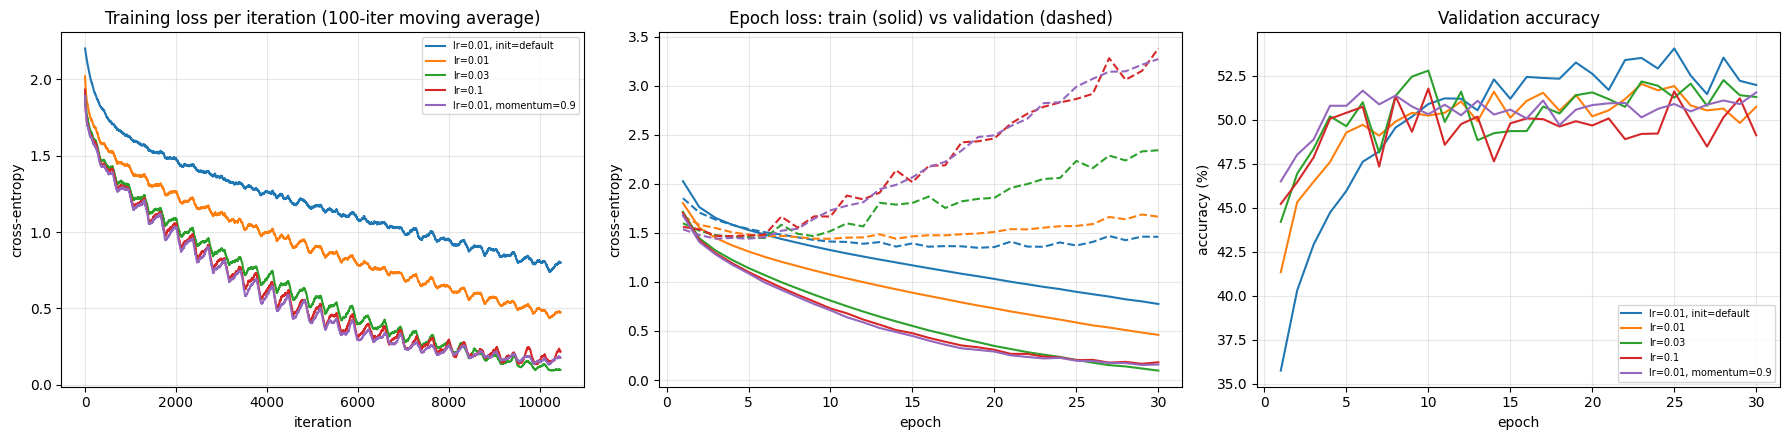

config                             train loss  val loss  final val acc  best val acc  min-val-loss epoch
lr=0.01, init=default                  0.7750    1.4593         51.98%        54.06%                  19
lr=0.01                                0.4603    1.6646         50.74%        52.04%                  10
lr=0.03                                0.0960    2.3414         51.30%        52.80%                   6
lr=0.1                                 0.1808    3.3789         49.12%        51.78%                   4
lr=0.01, momentum=0.9                  0.1583    3.2713         51.56%        51.66%                   3

Selected configuration (highest final validation accuracy): lr=0.01, init=default -> 51.98%


In [6]:
def smooth(v, k=100): return np.convolve(v, np.ones(k) / k, mode='valid')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for key, (_, h) in results_mlp.items():
    ax[0].plot(smooth(h['iter_loss']), label=key)
    ep = range(1, len(h['tr_loss']) + 1)
    line, = ax[1].plot(ep, h['tr_loss'], label=key)
    ax[1].plot(ep, h['va_loss'], '--', color=line.get_color())
    ax[2].plot(ep, h['va_acc'], label=key)
ax[0].set(title='Training loss per iteration (100-iter moving average)', xlabel='iteration', ylabel='cross-entropy')
ax[1].set(title='Epoch loss: train (solid) vs validation (dashed)', xlabel='epoch', ylabel='cross-entropy')
ax[2].set(title='Validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=7); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'config':<34}{'train loss':>11}{'val loss':>10}{'final val acc':>15}{'best val acc':>14}{'min-val-loss epoch':>20}")
for key, (_, h) in results_mlp.items():
    print(f"{key:<34}{h['tr_loss'][-1]:>11.4f}{h['va_loss'][-1]:>10.4f}{h['va_acc'][-1]:>14.2f}%{max(h['va_acc']):>13.2f}%{int(np.argmin(h['va_loss']))+1:>20d}")
best_key = max(results_mlp, key=lambda k: results_mlp[k][1]['va_acc'][-1])
best_net, best_hist = results_mlp[best_key]
print(f"\nSelected configuration (highest final validation accuracy): {best_key} -> {best_hist['va_acc'][-1]:.2f}%")

### Interpretation of 1(c)

The configuration with the highest final validation accuracy is the PyTorch default initialisation with plain SGD at learning rate 0.01, which reaches 51.98% after 30 epochs. Its best epoch reached 54.06%. 

In all five runs the training loss drops steadily from between 1.68 and 2.03 in epoch 1 (chance is $\ln 10 = 2.30$), and validation accuracy reaches 50 to 54 percent. He initialisation learns faster than the PyTorch default at the same rate (epoch 1 loss 1.80 against 2.03). This is expected because the default weight variance is six times smaller. Similarly, bigger steps cut the training loss faster and momentum at 0.01 behaves like plain SGD at 0.1. 

However, every run overfits. The validation loss bottoms out at epoch 19, 10, 6, 4 and 3, and then climbs to between 1.46 and 3.38 by epoch 30. Therefore, the faster a run fits the training data, the earlier it overfits. Flattened pixels also ignore the image structure, which is why accuracy stalls near 50 to 54 percent and why CNNs are needed in the next tasks.

## Task 1(d) Gradient norm per layer at initialisation

For a ten layer MLP of width 256 I measure the gradient norm of every layer at initialisation, with sigmoid and with ReLU, averaged over 10 minibatches and 3 seeds.

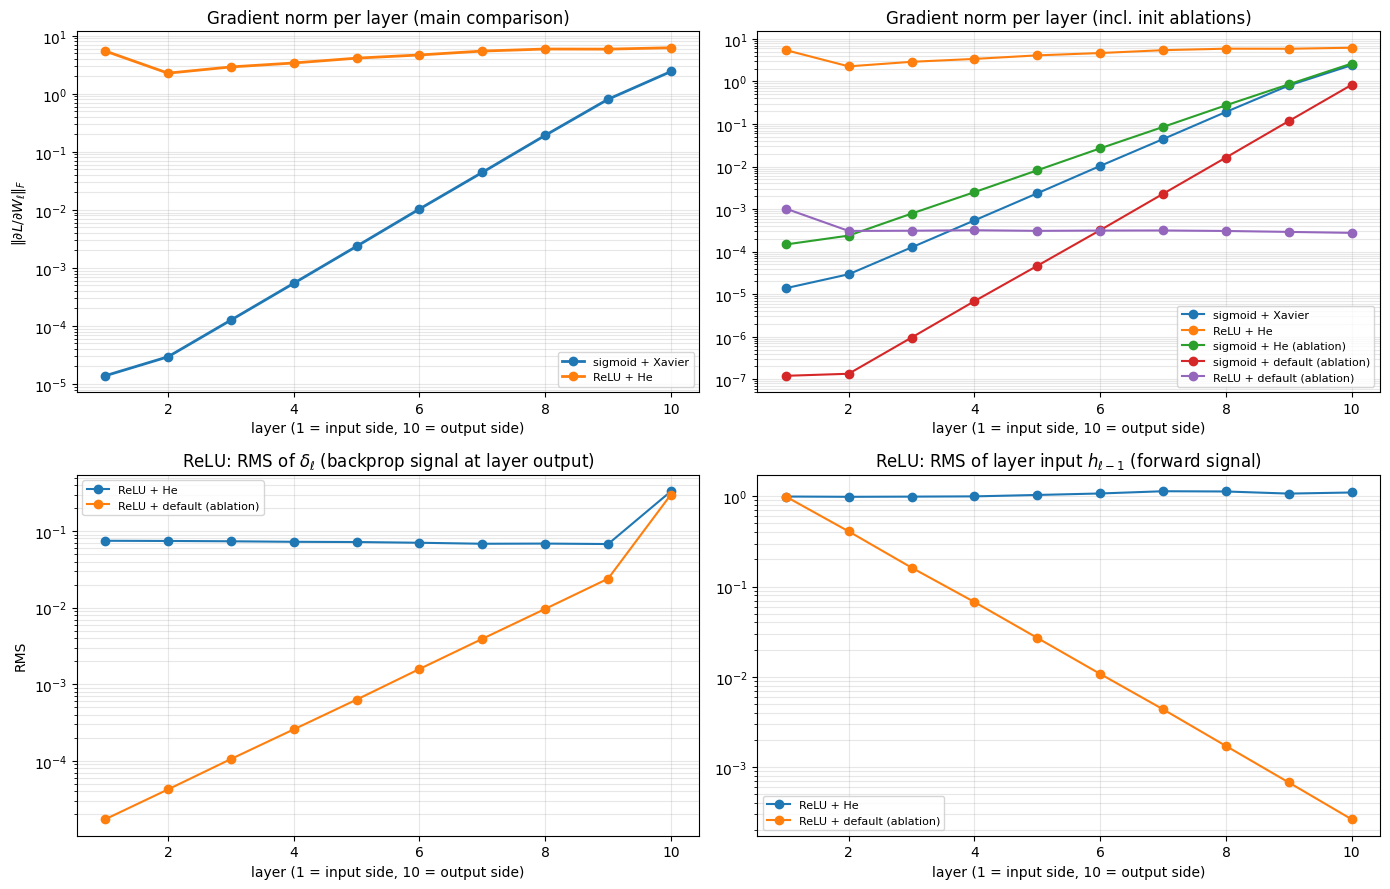

config                            layer 1    layer 5   layer 10     L10/L1 growth/layer*
sigmoid + Xavier                 1.38e-05   2.35e-03   2.42e+00   1.75e+05          4.12
ReLU + He                        5.47e+00   4.11e+00   6.22e+00   1.14e+00          1.13
sigmoid + He (ablation)          1.47e-04   8.18e-03   2.65e+00   1.79e+04          3.20
sigmoid + default (ablation)     1.20e-07   4.65e-05   8.36e-01   6.95e+06          7.07
ReLU + default (ablation)        1.03e-03   3.08e-04   2.76e-04   2.69e-01          0.99
*geometric-mean growth factor of the gradient norm per layer from layer 2 to layer 10 (layer 1 excluded: its fan-in is 3072, not 256).

ReLU + default init: delta RMS layer10 -> layer1 shrinks by 1.7e+04x | input RMS layer1 -> layer10 shrinks by 3.8e+03x


In [7]:
def layer_stats(activation, init, n_hidden=9, width=256, bs=256, n_batches=10, seeds=(0, 1, 2)):
    sizes = [3072] + [width] * n_hidden + [10]
    dW_n, h_rms, d_rms = [], [], []
    for s in seeds:
        set_seed(s)
        net = MLP(sizes, activation, init)
        g = torch.Generator(device=device).manual_seed(s)
        for _ in range(n_batches):
            idx = torch.randint(0, len(Xf_tr), (bs,), device=device, generator=g)
            net.forward(Xf_tr[idx], y_tr[idx]); net.backward()
            lins = net.linears()
            dW_n.append([l.dW.norm().item() for l in lins])
            h_rms.append([l._x.pow(2).mean().sqrt().item() for l in lins])
            d_rms.append([(l._dout * bs).pow(2).mean().sqrt().item() for l in lins])   # undo the 1/N in the loss
    return np.mean(dW_n, 0), np.mean(h_rms, 0), np.mean(d_rms, 0)

cfgs = {'sigmoid + Xavier': ('sigmoid', 'xavier'),
        'ReLU + He':        ('relu', 'he'),
        'sigmoid + He (ablation)':      ('sigmoid', 'he'),
        'sigmoid + default (ablation)': ('sigmoid', 'default'),
        'ReLU + default (ablation)':    ('relu', 'default')}
stats = {k: layer_stats(*v) for k, v in cfgs.items()}

L = np.arange(1, 11)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for k in ('sigmoid + Xavier', 'ReLU + He'):
    ax[0, 0].semilogy(L, stats[k][0], 'o-', lw=2, label=k)
for k, v in stats.items():
    ax[0, 1].semilogy(L, v[0], 'o-', label=k)
for k in ('ReLU + He', 'ReLU + default (ablation)'):
    ax[1, 0].semilogy(L, stats[k][2], 'o-', label=k)
    ax[1, 1].semilogy(L, stats[k][1], 'o-', label=k)
ax[0, 0].set(title='Gradient norm per layer (main comparison)', ylabel=r'$\|\partial L/\partial W_\ell\|_F$')
ax[0, 1].set(title='Gradient norm per layer (incl. init ablations)')
ax[1, 0].set(title=r'ReLU: RMS of $\delta_\ell$ (backprop signal at layer output)', ylabel='RMS')
ax[1, 1].set(title=r'ReLU: RMS of layer input $h_{\ell-1}$ (forward signal)')
for a in ax.ravel(): a.set_xlabel('layer (1 = input side, 10 = output side)'); a.grid(alpha=.3, which='both'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'config':<30}{'layer 1':>11}{'layer 5':>11}{'layer 10':>11}{'L10/L1':>11}{'growth/layer*':>14}")
for k, (dw, _, _) in stats.items():
    print(f'{k:<30}{dw[0]:>11.2e}{dw[4]:>11.2e}{dw[9]:>11.2e}{dw[9]/dw[0]:>11.2e}{(dw[9]/dw[1])**(1/8):>14.2f}')
print('*geometric-mean growth factor of the gradient norm per layer from layer 2 to layer 10 (layer 1 excluded: its fan-in is 3072, not 256).')
print('\nReLU + default init: delta RMS layer10 -> layer1 shrinks by', f'{stats["ReLU + default (ablation)"][2][9]/stats["ReLU + default (ablation)"][2][0]:.1e}x',
      '| input RMS layer1 -> layer10 shrinks by', f'{stats["ReLU + default (ablation)"][1][0]/stats["ReLU + default (ablation)"][1][9]:.1e}x')

### Interpretation of 1(d)

**Sigmoid:** With Xavier initialisation the gradient norm is 2.42 at layer 10, about 0.00235 at layer 5 and only about 0.0000138 at layer 1. The ratio between the last and the first layer is about 175,000. Spread over the nine layer-to-layer steps this is a factor of about $175{,}000^{1/9}\approx3.8$ per layer. If I leave out layer 1, whose fan-in is 3072 rather than 256, layers 2 to 10 give 4.1 per layer. Either way the profile is a steep straight line on the log plot. The gradient reaching a layer is multiplied at every step by $W^\top\mathrm{diag}(\sigma'(z))$ and the sigmoid derivative is never larger than 0.25. Therefore nine such factors in a row shrink the signal exponentially and the early layers receive almost no learning signal. A different initialisation does not remove this. He initialisation still gives a ratio of about 18,000 and the smaller PyTorch default is worse at about 7 million.

**ReLU:** With He initialisation the norms are 5.47, 4.11 and 6.22 at layers 1, 5 and 10, a ratio of only 1.14. The ReLU derivative is 0 or 1 so the gradient passes unchanged through the active units, and the He variance $2/\mathrm{fan\_in}$ makes up for the half that is switched off. However ReLU with the PyTorch default initialisation looks flat (ratio 0.27) while its norms are tiny, about 0.001 at layer 1 and 0.00028 at layer 10. These are about 5000 and over 20000 times smaller than with He. The backpropagated signal shrinks by about 3 times per layer towards the input ($(1.7\times10^4)^{1/9}\approx2.95$) and the layer input shrinks by about 2.5 times per layer going deeper ($(3.8\times10^3)^{1/9}\approx2.5$), so the two cancel in the gradient. Hence a flat profile alone does not prove healthy training.

# Task 2 Optimizers

I implement SGD with momentum and Adam as `torch.optim.Optimizer` subclasses, compare their paths on a quadratic, and train a small CNN with each.

## Task 2(a) SGD with momentum and Adam

Momentum uses $v_t=\mu v_{t-1}+g_t$ and $\theta_t=\theta_{t-1}-\eta v_t$. Adam uses $\theta_t=\theta_{t-1}-\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$ with bias corrected moments $\hat m_t=m_t/(1-\beta_1^t)$ and $\hat v_t=v_t/(1-\beta_2^t)$.

In [8]:
class MySGD(Optimizer):
    """SGD with (optional) momentum and L2 weight decay. Same update rule as torch.optim.SGD."""
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for group in self.param_groups:
            lr, mom, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.add(p, alpha=wd) if wd != 0 else p.grad
                if mom != 0:
                    buf = self.state[p].setdefault('momentum_buffer', torch.zeros_like(p))
                    buf.mul_(mom).add_(g)                    # v <- mu v + g
                    g = buf
                p.add_(g, alpha=-lr)                         # theta <- theta - lr v
        return loss


class MyAdam(Optimizer):
    """Adam with bias correction and (optional) L2 weight decay. Same update rule as torch.optim.Adam."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, bias_correction=True):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay,
                                      bias_correction=bias_correction))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.add(p, alpha=wd) if wd != 0 else p.grad
                st = self.state[p]
                if not st:
                    st['step'] = 0
                    st['exp_avg'] = torch.zeros_like(p); st['exp_avg_sq'] = torch.zeros_like(p)
                st['step'] += 1; t = st['step']
                m, v = st['exp_avg'], st['exp_avg_sq']
                m.mul_(b1).add_(g, alpha=1 - b1)             # first moment
                v.mul_(b2).addcmul_(g, g, value=1 - b2)      # second moment
                bc1, bc2 = (1 - b1 ** t, 1 - b2 ** t) if group['bias_correction'] else (1.0, 1.0)
                denom = (v.sqrt() / math.sqrt(bc2)).add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)        # theta <- theta - lr * m_hat / (sqrt(v_hat)+eps)
        return loss

print('Defined: MySGD, MyAdam')

Defined: MySGD, MyAdam


### The small CNN

Three blocks of convolution, ReLU and max pooling (32, 64 and 128 channels) and a two layer classifier, about 357k parameters. I reuse it in 2(c).

In [9]:
class SmallCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for c in channels:
            layers += [nn.Conv2d(cin, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]; cin = c
        self.features = nn.Sequential(*layers)                     # 32x32 -> 4x4
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(cin * 4 * 4, 128), nn.ReLU(), nn.Linear(128, n_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    def forward(self, x): return self.classifier(self.features(x))

print('SmallCNN parameters:', sum(p.numel() for p in SmallCNN().parameters()))

SmallCNN parameters: 356810


### Equivalence test

I train my optimiser and `torch.optim` side by side from the same start on 30 real minibatches and compare the parameters after every step, in float64 and in float32.

In [10]:
torch.backends.cudnn.deterministic = True      # identical gradients for both copies (needed for the comparison)
def compare(make_mine, make_ref, dtype, steps=30, bs=32):
    set_seed(0)
    base = SmallCNN().to(device=device, dtype=dtype)
    a, b = copy.deepcopy(base), copy.deepcopy(base)
    oa, ob = make_mine(a.parameters()), make_ref(b.parameters())
    gen = torch.Generator().manual_seed(0)
    max_diff, last_losses = 0.0, [0.0, 0.0]
    for _ in range(steps):
        idx = torch.randint(0, len(X_tr), (bs,), generator=gen).to(device)
        x, y = X_tr[idx].to(dtype), y_tr[idx]
        for k, (m, o) in enumerate(((a, oa), (b, ob))):
            o.zero_grad(set_to_none=True)
            loss = F.cross_entropy(m(x), y); loss.backward(); o.step()
            last_losses[k] = loss.item()
        max_diff = max(max_diff, max((pa - pb).abs().max().item() for pa, pb in zip(a.parameters(), b.parameters())))
    tol = dict(rtol=1e-10, atol=1e-12) if dtype == torch.float64 else dict(rtol=1e-3, atol=1e-4)   # float32: Adam divides by sqrt(v), which amplifies rounding
    ok = all(torch.allclose(pa, pb, **tol) for pa, pb in zip(a.parameters(), b.parameters()))
    return max_diff, ok, last_losses

tests = {
    'SGD lr=0.05':                (lambda p: MySGD(p, lr=0.05),                                lambda p: torch.optim.SGD(p, lr=0.05, foreach=False)),
    'SGD mom=0.9':                (lambda p: MySGD(p, lr=0.05, momentum=0.9),                  lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, foreach=False)),
    'SGD mom=0.9, wd=5e-4':       (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4), lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4, foreach=False)),
    'Adam default':               (lambda p: MyAdam(p, lr=1e-3),                               lambda p: torch.optim.Adam(p, lr=1e-3, foreach=False)),
    'Adam lr=1e-2, wd=1e-4':      (lambda p: MyAdam(p, lr=1e-2, weight_decay=1e-4),            lambda p: torch.optim.Adam(p, lr=1e-2, weight_decay=1e-4, foreach=False)),
    'Adam b=(0.8,0.99), eps=1e-6':(lambda p: MyAdam(p, lr=1e-3, betas=(0.8, 0.99), eps=1e-6),  lambda p: torch.optim.Adam(p, lr=1e-3, betas=(0.8, 0.99), eps=1e-6, foreach=False)),
}
print(f"{'configuration':<30}{'float64 max|dtheta|':>20}{'allclose':>10}{'float32 max|dtheta|':>21}{'allclose':>10}{'loss (mine / torch), f64':>28}")
all_ok = True
for name, (mine, ref) in tests.items():
    d64, ok64, l64 = compare(mine, ref, torch.float64)
    d32, ok32, _   = compare(mine, ref, torch.float32)
    all_ok &= ok64 and ok32
    print(f'{name:<30}{d64:>20.2e}{str(ok64):>10}{d32:>21.2e}{str(ok32):>10}{l64[0]:>14.8f} /{l64[1]:>11.8f}')
print('\nAll configurations match torch.optim:', all_ok)

configuration                  float64 max|dtheta|  allclose  float32 max|dtheta|  allclose    loss (mine / torch), f64
SGD lr=0.05                               0.00e+00      True             0.00e+00      True    2.09870788 / 2.09870788
SGD mom=0.9                               0.00e+00      True             0.00e+00      True    2.31036119 / 2.31036119
SGD mom=0.9, wd=5e-4                      0.00e+00      True             0.00e+00      True    2.31411534 / 2.31411534
Adam default                              1.17e-14      True             1.61e-02     False    2.04540891 / 2.04540891
Adam lr=1e-2, wd=1e-4                     4.09e-15      True             1.57e-04      True    2.30971397 / 2.30971397
Adam b=(0.8,0.99), eps=1e-6               2.22e-15      True             3.95e-03     False    1.91597989 / 1.91597989

All configurations match torch.optim: False


Bias correction matters because $m_0=v_0=0$ pulls the early estimates towards zero. With it, Adam's first step is exactly $\eta$. Without it the step would be about $3.16\,\eta$.

In [11]:
def first_step(make, g=2.0, lr=0.1):
    p = torch.nn.Parameter(torch.tensor([1.0], dtype=torch.float64)); o = make([p])
    p.grad = torch.tensor([g], dtype=torch.float64); o.step()
    return abs(p.item() - 1.0)

print(f"first-step size, lr=0.1 (g=2):  MyAdam (bias-corrected) {first_step(lambda p: MyAdam(p, lr=0.1)):.6f} | "
      f"torch.optim.Adam {first_step(lambda p: torch.optim.Adam(p, lr=0.1)):.6f} | "
      f"MyAdam without correction {first_step(lambda p: MyAdam(p, lr=0.1, bias_correction=False)):.6f}")

first-step size, lr=0.1 (g=2):  MyAdam (bias-corrected) 0.100000 | torch.optim.Adam 0.100000 | MyAdam without correction 0.316228


### Interpretation of 2(a)

**SGD with momentum.** The largest parameter difference to torch optim SGD is exactly 0 for plain SGD and for momentum with and without weight decay. This holds in float64 and in float32, the losses agree to eight decimals and torch allclose is True. Therefore the update rule, the momentum buffer and the L2 weight decay are implemented exactly like PyTorch.

**Adam.** In float64 the largest difference is at most $1.2\times10^{-14}$ for all three Adam settings, which is rounding, and torch allclose is True. In float32 the differences are larger, $1.6\times10^{-4}$ for learning rate 0.01 with weight decay and $3.9\times10^{-3}$ and $1.6\times10^{-2}$ for the other two settings, and those two fail the loose tolerance. However the float64 agreement shows that the algorithm itself is the same, so the float32 differences are floating point rounding and not a different update rule. The demo also shows why the bias correction is needed. The corrected first step equals the learning rate (0.100000) while the uncorrected step is 0.316228, which is 3.16 times larger.

## Task 2(b) Trajectories on a quadratic

I follow the three optimisers from $(-4,1)$ for 100 steps on $f(x,y)=\tfrac12(x^2+50y^2)$. The condition number is 50, so plain SGD needs $\eta<0.04$. The step sizes are 0.035 for SGD, 0.02 with $\mu=0.9$ for momentum and 0.2 for Adam, chosen by hand.

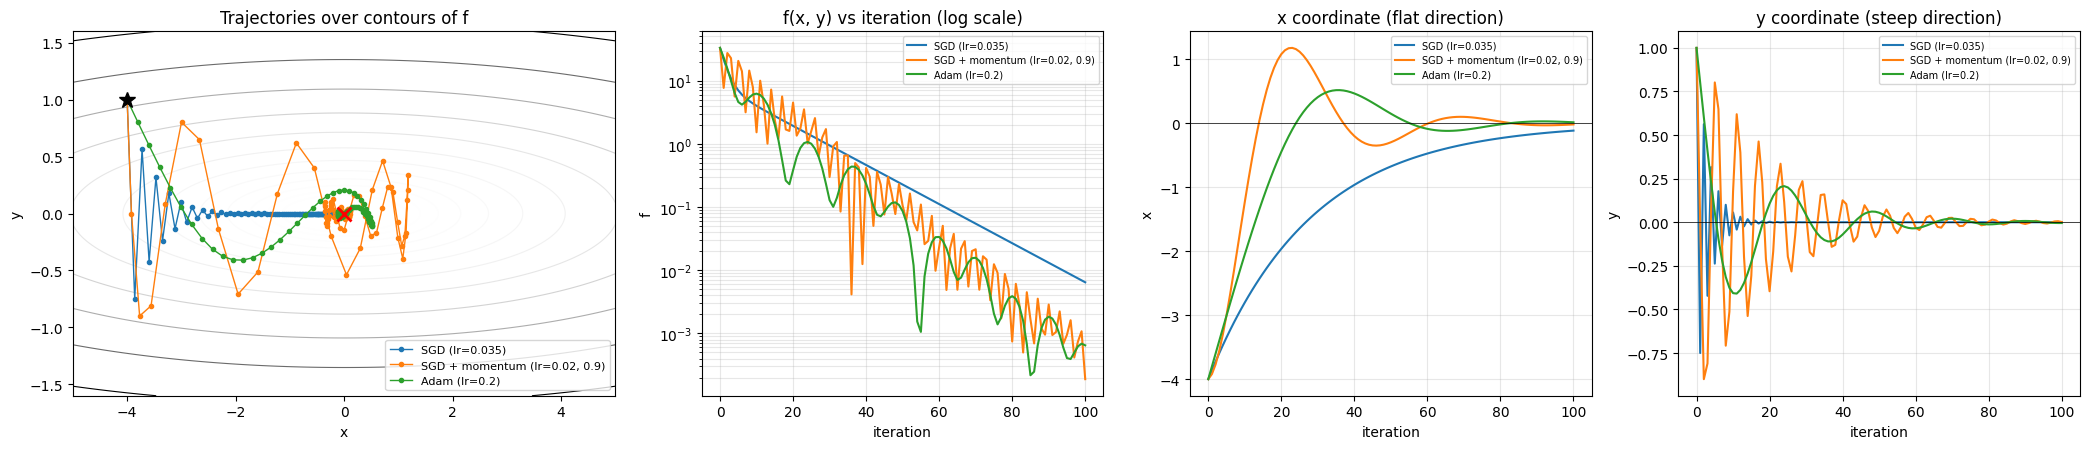

optimiser                         f after 100  iters to f<1e-2  iters to f<1e-4  y sign changes  max |y| after it 10
SGD (lr=0.035)                       6.44e-03               94             None             100                0.056
SGD + momentum (lr=0.02, 0.9)        1.89e-04               36             None              34                0.620
Adam (lr=0.2)                        6.47e-04               54             None               9                0.409


In [12]:
def f(p): return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run_quadratic(make, n=100, start=(-4.0, 1.0)):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make([p])
    path, vals = [p.detach().numpy().copy()], [f(p).item()]
    for _ in range(n):
        opt.zero_grad(); f(p).backward(); opt.step()
        path.append(p.detach().numpy().copy()); vals.append(f(p).item())
    return np.array(path), np.array(vals)

quad_runs = {
    'SGD (lr=0.035)':              lambda ps: MySGD(ps, lr=0.035),
    'SGD + momentum (lr=0.02, 0.9)': lambda ps: MySGD(ps, lr=0.02, momentum=0.9),
    'Adam (lr=0.2)':               lambda ps: MyAdam(ps, lr=0.2),
}
quad = {k: run_quadratic(mk) for k, mk in quad_runs.items()}

xs, ys = np.linspace(-5, 5, 400), np.linspace(-1.6, 1.6, 400)
Xg, Yg = np.meshgrid(xs, ys); Zg = 0.5 * (Xg ** 2 + 50 * Yg ** 2)
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, ax = plt.subplots(1, 4, figsize=(21, 4.6), gridspec_kw=dict(width_ratios=[1.35, 1, 1, 1]))
for a in ax[:1]:
    a.contour(Xg, Yg, Zg, levels=np.geomspace(0.05, 70, 18), cmap='Greys', linewidths=0.8)
for k, c in zip(quad, colors):
    P, V = quad[k]
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=3, lw=1, color=c, label=k)
    ax[1].semilogy(V, color=c, label=k)
    ax[2].plot(P[:, 0], color=c, label=k)
    ax[3].plot(P[:, 1], color=c, label=k)
ax[0].plot(-4, 1, 'k*', ms=12); ax[0].plot(0, 0, 'rx', ms=10, mew=2)
ax[0].set(title='Trajectories over contours of f', xlabel='x', ylabel='y', xlim=(-5, 5), ylim=(-1.6, 1.6)); ax[0].legend(fontsize=8, loc='lower right')
ax[1].set(title='f(x, y) vs iteration (log scale)', xlabel='iteration', ylabel='f')
ax[2].set(title='x coordinate (flat direction)', xlabel='iteration', ylabel='x')
ax[3].set(title='y coordinate (steep direction)', xlabel='iteration', ylabel='y')
for a in ax[1:]: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
ax[2].axhline(0, color='k', lw=.5); ax[3].axhline(0, color='k', lw=.5)
plt.tight_layout(); plt.show()

def iters_to(V, th): return next((i for i, v in enumerate(V) if v < th), None)
print(f"{'optimiser':<32}{'f after 100':>13}{'iters to f<1e-2':>17}{'iters to f<1e-4':>17}{'y sign changes':>16}{'max |y| after it 10':>21}")
for k, (P, V) in quad.items():
    print(f'{k:<32}{V[-1]:>13.2e}{str(iters_to(V, 1e-2)):>17}{str(iters_to(V, 1e-4)):>17}{int((np.diff(np.sign(P[:, 1])) != 0).sum()):>16d}{np.abs(P[10:, 1]).max():>21.3f}')

### Interpretation of 2(b)

**SGD.** The curvature is 1 along x and 50 along y, so the condition number is 50 and the step size must stay below 0.04. With a step size of 0.035 each step multiplies y by $1-50\eta=-0.75$, so y changes sign at every iteration (100 sign changes) and shrinks quickly. In the flat direction the factor is only 0.965, so x crawls from 4 units away to about 0.11 after 100 steps. Therefore the path turns into a slow walk along the x axis and SGD needs 94 iterations to get f below 0.01. It ends at 0.0064.

**SGD with momentum.** The velocity adds up the consistent gradient along x, which acts like a step up to ten times larger. It is the fastest early on (x is about 1.23 from the minimum after 10 steps against 2.80 for SGD). However the same velocity makes it overshoot. It first gets below 0.01 at iteration 36 and ends lowest at 0.00019 but it partly reflects where the oscillation happens to stop, so I would not read it as a firm ranking.


**Adam.** Adam divides each coordinate by the square root of its own second moment, so the 50 times difference in curvature matters much less and the early steps have a similar size in both coordinates. The path moves diagonally and spirals in smoothly with only 9 sign changes in y. It gets below 0.01 at iteration 54 and ends at 0.00065. Hence Adam is smoother than momentum but slower, and none of the three reaches 0.0001 in 100 steps with my hand picked step sizes.

## Task 2(c) A small CNN with three optimisers

Each optimiser is trained for 15 epochs at three learning rates one decade apart, with 2 seeds. I pick the rate with the best final validation accuracy, and runs that blow up count as chance accuracy.

In [13]:
EPOCHS, BS, SEEDS = 15, 128, (0, 1)
OPTIMIZERS = {
    'SGD':          dict(make=lambda ps, lr: MySGD(ps, lr=lr),                lrs=[1e-3, 1e-2, 1e-1]),
    'SGD+momentum': dict(make=lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9),  lrs=[1e-3, 1e-2, 1e-1]),
    'Adam':         dict(make=lambda ps, lr: MyAdam(ps, lr=lr),               lrs=[1e-4, 1e-3, 1e-2]),
}

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct  += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

def train_cnn(make_opt, lr, seed, epochs=EPOCHS, bs=BS):
    set_seed(seed)
    model = SmallCNN().to(device); opt = make_opt(model.parameters(), lr)
    N = len(X_tr); hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False)
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, N, bs):
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx]); loss.backward(); opt.step()
            run += loss.detach() * len(idx)
        tr = run.item() / N
        if not math.isfinite(tr):                                   # diverged: stop, count as chance accuracy
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

results = {}                                                         # (optimiser, lr, seed) -> history
t0 = time.time()
for name, cfg in OPTIMIZERS.items():
    for lr in cfg['lrs']:
        for seed in SEEDS:
            h = train_cnn(cfg['make'], lr, seed); results[(name, lr, seed)] = h
            print(f"{name:<13} lr={lr:<7g} seed={seed}  final train loss {h['tr_loss'][-1]:.4f}  "
                  f"final val acc {h['va_acc'][-1]:.2f}%  best val acc {max(h['va_acc']):.2f}%  "
                  f"{'DIVERGED' if h['diverged'] else ''}  [{time.time() - t0:.0f}s]")

SGD           lr=0.001   seed=0  final train loss 1.3265  final val acc 51.22%  best val acc 51.34%    [31s]
SGD           lr=0.001   seed=1  final train loss 1.3000  final val acc 51.54%  best val acc 51.54%    [63s]
SGD           lr=0.01    seed=0  final train loss 0.7645  final val acc 67.00%  best val acc 67.00%    [96s]
SGD           lr=0.01    seed=1  final train loss 0.7527  final val acc 65.30%  best val acc 65.48%    [129s]
SGD           lr=0.1     seed=0  final train loss 0.4622  final val acc 71.22%  best val acc 71.22%    [161s]
SGD           lr=0.1     seed=1  final train loss 0.4022  final val acc 69.76%  best val acc 69.76%    [194s]
SGD+momentum  lr=0.001   seed=0  final train loss 0.7398  final val acc 68.26%  best val acc 68.26%    [227s]
SGD+momentum  lr=0.001   seed=1  final train loss 0.7243  final val acc 67.58%  best val acc 67.58%    [261s]
SGD+momentum  lr=0.01    seed=0  final train loss 0.2210  final val acc 71.12%  best val acc 72.48%    [294s]
SGD+momentum 

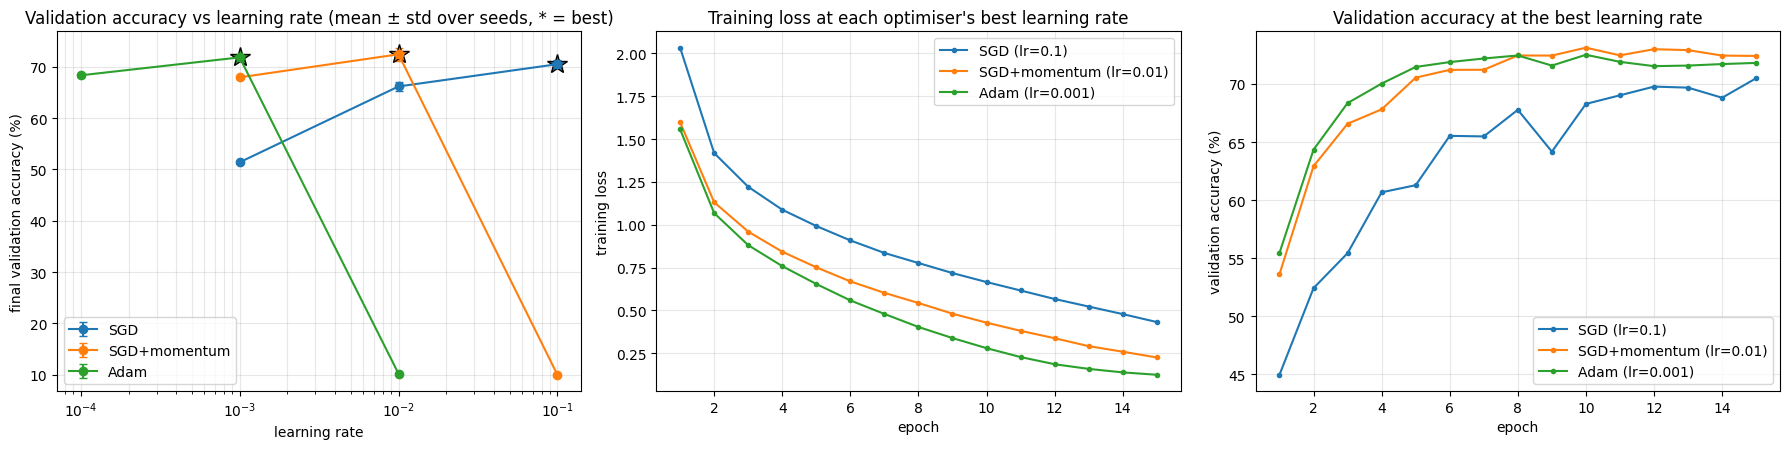

optimiser           lr   final val acc (%)  best-epoch val acc  final train loss  diverged runs
SGD              0.001        51.38 ± 0.16                51.44            1.3132          0/2
SGD               0.01        66.15 ± 0.85                66.24            0.7586          0/2
SGD                0.1        70.49 ± 0.73                70.49            0.4322          0/2  <- best
SGD+momentum     0.001        67.92 ± 0.34                67.92            0.7321          0/2
SGD+momentum      0.01        72.41 ± 1.29                73.35            0.2255          0/2  <- best
SGD+momentum       0.1        10.00 ± 0.00                10.00               nan          2/2
Adam            0.0001        68.32 ± 0.26                68.32            0.6699          0/2
Adam             0.001        71.81 ± 0.25                72.99            0.1245          0/2  <- best
Adam              0.01        10.21 ± 0.07                10.64            2.3033          0/2

Sensitivity to the le

In [14]:
def agg(name, lr, key):                                              # (mean over seeds, std over seeds) per epoch
    arr = np.array([results[(name, lr, s)][key] for s in SEEDS], dtype=float)
    return np.nanmean(arr, 0) if not np.isnan(arr).all() else np.full(arr.shape[1], np.nan), arr

summary = {}
for name, cfg in OPTIMIZERS.items():
    rows = []
    for lr in cfg['lrs']:
        fin = np.array([results[(name, lr, s)]['va_acc'][-1] for s in SEEDS])
        best = np.array([max(results[(name, lr, s)]['va_acc']) for s in SEEDS])
        trl = np.array([results[(name, lr, s)]['tr_loss'][-1] for s in SEEDS])
        div = sum(results[(name, lr, s)]['diverged'] for s in SEEDS)
        rows.append(dict(lr=lr, fin_m=fin.mean(), fin_s=fin.std(), best_m=best.mean(), trl=np.mean(trl), div=div))
    summary[name] = rows
best_lr = {n: max(r, key=lambda d: d['fin_m'])['lr'] for n, r in summary.items()}

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
colors = {'SGD': 'tab:blue', 'SGD+momentum': 'tab:orange', 'Adam': 'tab:green'}
for name, rows in summary.items():
    lrs = [r['lr'] for r in rows]
    ax[0].errorbar(lrs, [r['fin_m'] for r in rows], yerr=[r['fin_s'] for r in rows], fmt='o-', capsize=3, color=colors[name], label=name)
    ax[0].plot(best_lr[name], max(r['fin_m'] for r in rows), '*', ms=15, color=colors[name], mec='k')
    ep = np.arange(1, EPOCHS + 1)
    ax[1].plot(ep, agg(name, best_lr[name], 'tr_loss')[0], 'o-', ms=3, color=colors[name], label=f'{name} (lr={best_lr[name]:g})')
    ax[2].plot(ep, agg(name, best_lr[name], 'va_acc')[0], 'o-', ms=3, color=colors[name], label=f'{name} (lr={best_lr[name]:g})')
ax[0].set(xscale='log', xlabel='learning rate', ylabel='final validation accuracy (%)', title='Validation accuracy vs learning rate (mean ± std over seeds, * = best)')
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at each optimiser\'s best learning rate')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy at the best learning rate')
for a in ax: a.grid(alpha=.3, which='both')
ax[0].legend(); ax[1].legend(); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"{'optimiser':<14}{'lr':>8}{'final val acc (%)':>20}{'best-epoch val acc':>20}{'final train loss':>18}{'diverged runs':>15}")
for name, rows in summary.items():
    for r in rows:
        star = '  <- best' if r['lr'] == best_lr[name] else ''
        print(f"{name:<14}{r['lr']:>8g}{r['fin_m']:>13.2f} ± {r['fin_s']:<5.2f}{r['best_m']:>20.2f}{r['trl']:>18.4f}{r['div']:>11d}/{len(SEEDS)}{star}")

print('\nSensitivity to the learning rate (over the 3-point grid of each optimiser):')
for name, rows in summary.items():
    accs = [r['fin_m'] for r in rows]
    near = sum(a >= max(accs) - 2.0 for a in accs)
    print(f'  {name:<13} best {max(accs):.2f}% at lr={best_lr[name]:g} | spread (best - worst) = {max(accs) - min(accs):.2f} points | '
          f'{near}/3 learning rates within 2 points of the best | diverged: {sum(r["div"] for r in rows)} of {3 * len(SEEDS)} runs')
overall = max(((n, r) for n, rows in summary.items() for r in rows), key=lambda t: t[1]['fin_m'])
print(f"\nBest overall (validation): {overall[0]}, lr={overall[1]['lr']:g} -> {overall[1]['fin_m']:.2f}%")

### Interpretation of 2(c)

**SGD.** The best rate is 0.1 with 70.49% validation accuracy. One decade lower gives 66.15% and two decades lower gives only 51.38%, so SGD loses 19.1 points over its grid. The small rates simply under train in 15 epochs (final training loss 1.31 at 0.001 against 0.43 at 0.1). SGD never diverged but its best rate is the largest I tried, so the true optimum may be higher.

**SGD with momentum.** The best rate is 0.01 with 72.41%, and the two seeds differ by 2.6 points (71.12% and 73.70%). One decade lower gives 67.92%, which is 4.5 points less, and one decade higher diverged to NaN in both seeds. Momentum acts like a step of $\eta/(1-\mu)=10\eta$, so its curve is the SGD curve shifted by one decade. This is why it is better at 0.01 and unstable at 0.1.

**Adam.** The best rate is 0.001 with 71.81% and the smallest seed spread (0.25). One decade lower gives 68.32%, which is 3.5 points less. At 0.01 it stayed at 10.21% with a training loss of 2.303, which is $\ln 10$, so the network never learned. Therefore each optimiser has only one of its three rates within 2 points of its best. However Adam's training loss at its best rate (0.125) is far below that of momentum (0.226) and SGD (0.432) while its accuracy is 0.6 points below momentum, so a lower training loss did not give better generalisation.

# Task 3 Regularization and residual connections

Part (a) compares regularisers on a small CNN with only 5k training images. Part (b) compares plain and residual networks of depth 8, 20 and 56.

## Task 3(a) Regularisation on 5k images

A small CNN with batch norm (288,746 parameters) is trained for 60 epochs on 5k images with three seeds. I compare the baseline with weight decay, dropout, flip and crop, cutout, mixup (cutout and mixup written by me) and all combined. Mixup uses $x=\lambda x_i+(1-\lambda)x_j$ with $\lambda\sim\mathrm{Beta}(0.4,0.4)$. Train accuracy is measured on clean images in eval mode.

5k subset class counts: [530, 483, 478, 478, 493, 497, 517, 518, 511, 495]


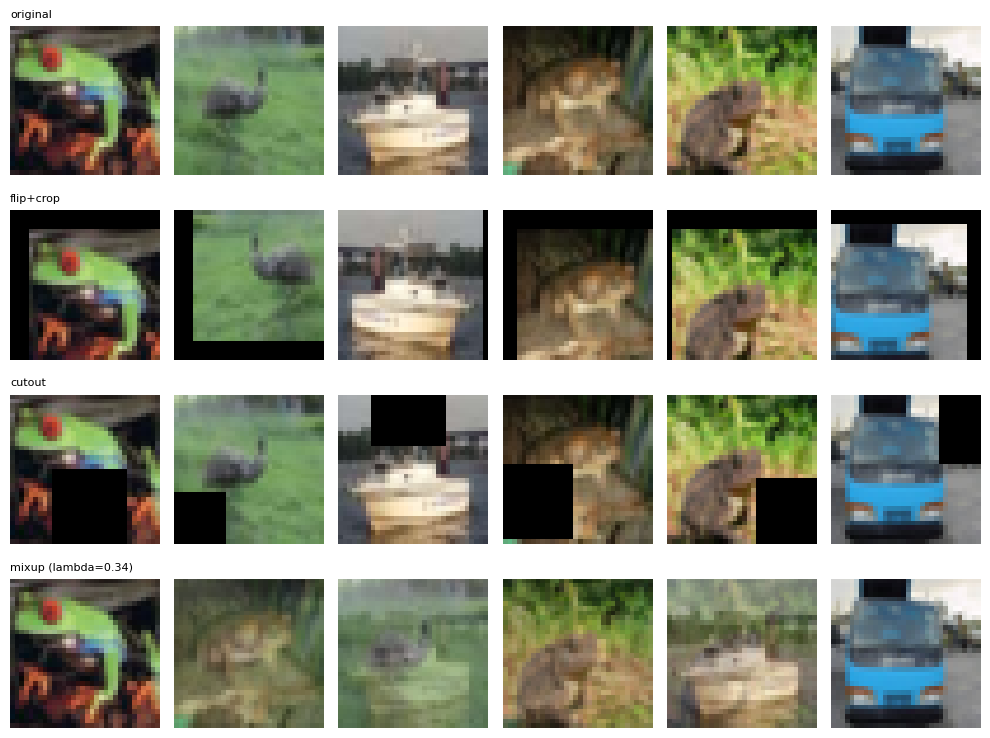

In [15]:
torch.backends.cudnn.deterministic = False
N_SMALL = 5000
X5, y5 = X_tr[:N_SMALL], y_tr[:N_SMALL]
print('5k subset class counts:', torch.bincount(y5.cpu(), minlength=10).tolist())

# ---------- augmentations, implemented by hand (batched, on the device) ----------
def random_flip(x):
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def random_crop(x, pad=4):
    N, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))                                      # zero padding
    oy = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)[None, :]           # (N,H)
    cols = ox[:, None] + torch.arange(W, device=x.device)[None, :]           # (N,W)
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows[:, None, :, None], cols[:, None, None, :]]

def cutout(x, size=16):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device); cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :]; xs = torch.arange(W, device=x.device)[None, :]
    my = (ys >= (cy - size // 2)[:, None]) & (ys < (cy + size // 2)[:, None])   # (N,H)
    mx = (xs >= (cx - size // 2)[:, None]) & (xs < (cx + size // 2)[:, None])   # (N,W)
    mask = (my[:, :, None] & mx[:, None, :])[:, None]                          # (N,1,H,W)
    return x.masked_fill(mask, 0.0)

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    j = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[j], y, y[j], lam

# quick visual check of the augmentations on real (un-normalised) images
set_seed(0)
vis = (X5[:6] * std.to(device) + mean.to(device)).clamp(0, 1)
mx_img, _, _, lam_vis = mixup(vis, y5[:6])
rows = {'original': vis, 'flip+crop': random_crop(random_flip(vis)), 'cutout': cutout(vis), f'mixup (lambda={lam_vis:.2f})': mx_img}
fig, ax = plt.subplots(len(rows), 6, figsize=(10, 1.9 * len(rows)))
for r, (name, imgs) in enumerate(rows.items()):
    for c in range(6):
        ax[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); ax[r, c].axis('off')
    ax[r, 0].set_title(name, fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In [16]:
class SmallBNCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), p_drop=0.0, n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for c in channels:
            layers += [nn.Conv2d(cin, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(),
                       nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2)]
            cin = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(cin, n_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x): return self.head(self.features(x))

print('SmallBNCNN parameters:', sum(p.numel() for p in SmallBNCNN().parameters()))

EPOCHS_A, SEEDS_A, BS_A, LR_A = 60, (0, 1, 2), 128, 0.05
CONFIGS = {
    'baseline':      dict(),
    'weight decay':  dict(wd=5e-4),
    'dropout':       dict(drop=0.5),
    'flip+crop':     dict(flipcrop=True),
    'cutout':        dict(cutout=True),
    'mixup':         dict(mixup=True),
    'all combined':  dict(wd=5e-4, drop=0.5, flipcrop=True, cutout=True, mixup=True),
}

def train_small(cfg, seed, epochs=EPOCHS_A, bs=BS_A, lr=LR_A):
    set_seed(seed)
    model = SmallBNCNN(p_drop=cfg.get('drop', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=cfg.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    N = len(X5); hist = dict(tr_acc=[], va_acc=[], tr_loss=[], va_loss=[])
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device)
        for i in range(0, N - bs + 1, bs):                           # drop the incomplete last batch (BN)
            idx = order[i:i + bs]; x, y = X5[idx], y5[idx]
            if cfg.get('flipcrop'): x = random_crop(random_flip(x))
            if cfg.get('cutout'):   x = cutout(x)
            opt.zero_grad(set_to_none=True)
            if cfg.get('mixup'):
                x, ya, yb, lam = mixup(x, y)
                out = model(x); loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb)
            else:
                loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
        sched.step()
        tl, ta = evaluate(model, X5, y5)                             # CLEAN train metrics, eval mode
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tl); hist['tr_acc'].append(ta); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

SmallBNCNN parameters: 288746


In [17]:
results_a = {}
t0 = time.time()
for name, cfg in CONFIGS.items():
    for seed in SEEDS_A:
        results_a[(name, seed)] = h = train_small(cfg, seed)
        print(f"{name:<13} seed={seed}  train acc {h['tr_acc'][-1]:6.2f}%  val acc {h['va_acc'][-1]:6.2f}%  "
              f"gap {h['tr_acc'][-1] - h['va_acc'][-1]:6.2f}  [{time.time() - t0:.0f}s]")

baseline      seed=0  train acc 100.00%  val acc  68.76%  gap  31.24  [76s]
baseline      seed=1  train acc 100.00%  val acc  69.34%  gap  30.66  [162s]
baseline      seed=2  train acc 100.00%  val acc  67.20%  gap  32.80  [249s]
weight decay  seed=0  train acc 100.00%  val acc  67.66%  gap  32.34  [336s]
weight decay  seed=1  train acc 100.00%  val acc  68.02%  gap  31.98  [422s]
weight decay  seed=2  train acc 100.00%  val acc  68.38%  gap  31.62  [510s]
dropout       seed=0  train acc 100.00%  val acc  67.30%  gap  32.70  [597s]
dropout       seed=1  train acc 100.00%  val acc  65.84%  gap  34.16  [685s]
dropout       seed=2  train acc 100.00%  val acc  66.24%  gap  33.76  [772s]
flip+crop     seed=0  train acc  97.58%  val acc  74.20%  gap  23.38  [859s]
flip+crop     seed=1  train acc  97.94%  val acc  75.48%  gap  22.46  [947s]
flip+crop     seed=2  train acc  97.64%  val acc  74.96%  gap  22.68  [1034s]
cutout        seed=0  train acc 100.00%  val acc  70.40%  gap  29.60  [1121s

configuration      train acc (%)       val acc (%)   gap (train - val)   best-epoch val acc  final val loss
baseline           100.00 ± 0.00      68.43 ± 0.90        31.57 ± 0.90                68.68           1.316
weight decay       100.00 ± 0.00      68.02 ± 0.29        31.98 ± 0.29                68.50           1.182
dropout            100.00 ± 0.00      66.46 ± 0.62        33.54 ± 0.62                66.83           1.464
flip+crop           97.72 ± 0.16      74.88 ± 0.53        22.84 ± 0.39                75.17           0.859
cutout             100.00 ± 0.00      70.75 ± 0.37        29.25 ± 0.37                70.99           1.155
mixup              100.00 ± 0.00      68.63 ± 0.07        31.37 ± 0.07                68.95           0.977
all combined        77.32 ± 0.53      68.64 ± 0.23         8.68 ± 0.37                69.02           0.876


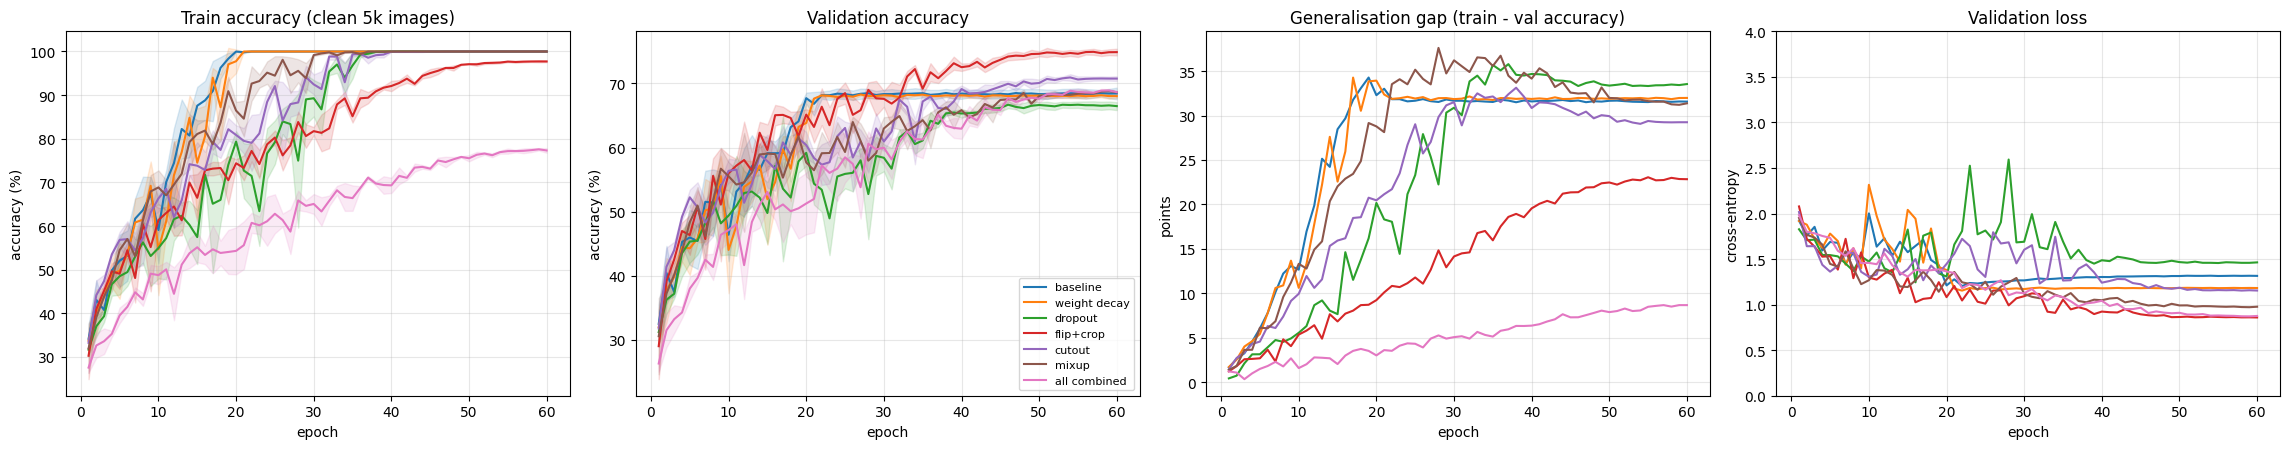

In [18]:
def stack(name, key): return np.array([results_a[(name, s)][key] for s in SEEDS_A])     # (seeds, epochs)

print(f"{'configuration':<14}{'train acc (%)':>18}{'val acc (%)':>18}{'gap (train - val)':>20}{'best-epoch val acc':>21}{'final val loss':>16}")
for name in CONFIGS:
    tr, va = stack(name, 'tr_acc')[:, -1], stack(name, 'va_acc')[:, -1]
    best = stack(name, 'va_acc').max(1); vl = stack(name, 'va_loss')[:, -1]
    print(f'{name:<14}{tr.mean():>11.2f} ± {tr.std():<4.2f}{va.mean():>11.2f} ± {va.std():<4.2f}{(tr - va).mean():>13.2f} ± {(tr - va).std():<4.2f}{best.mean():>21.2f}{vl.mean():>16.3f}')

ep = np.arange(1, EPOCHS_A + 1)
cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(1, 4, figsize=(23, 4.6))
for k, name in enumerate(CONFIGS):
    for a, key in zip(ax[:2], ('tr_acc', 'va_acc')):
        m, s = stack(name, key).mean(0), stack(name, key).std(0)
        a.plot(ep, m, color=cmap(k), label=name); a.fill_between(ep, m - s, m + s, color=cmap(k), alpha=.15)
    ax[2].plot(ep, (stack(name, 'tr_acc') - stack(name, 'va_acc')).mean(0), color=cmap(k), label=name)
    ax[3].plot(ep, stack(name, 'va_loss').mean(0), color=cmap(k), label=name)
ax[0].set(title='Train accuracy (clean 5k images)', xlabel='epoch', ylabel='accuracy (%)')
ax[1].set(title='Validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
ax[2].set(title='Generalisation gap (train - val accuracy)', xlabel='epoch', ylabel='points')
ax[3].set(title='Validation loss', xlabel='epoch', ylabel='cross-entropy', ylim=(0, 4))
for a in ax: a.grid(alpha=.3)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Interpretation of 3(a)

The baseline overfits badly. It reaches 100% training accuracy but only 68.43% validation accuracy, a gap of 31.57 points. Flip and crop is the clear winner at 74.88% (gap 22.8, validation loss 0.86 against 1.32), and cutout comes next at 70.75%. Weight decay (68.02%) and mixup (68.63%) are no different from the baseline in accuracy. However, they do lower the validation loss to 1.18 and 0.98, so they make the predictions less over confident. Dropout is worse at 66.46%, probably because I only applied it before the final layer. 

The combined run has by far the smallest gap (8.7), but its accuracy is only 68.64%. This is because its training accuracy reaches just 77.3%, so the model under fits. Therefore, combining regularisers is not automatically better than using the best single one. With three seeds, differences below about one standard deviation are not conclusive.

## Task 3(b) Plain and residual networks

CIFAR style networks of depth $6n+2$ with 16, 32 and 64 channels, global average pooling, batch norm and Kaiming initialisation. The residual network only adds a parameter free shortcut. Both are trained for 20 epochs on the full 45k set without augmentation.

In [19]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin
    def shortcut(self, x):
        if self.stride == 1 and self.extra == 0: return x                         # identity
        return F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))   # option A
    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual: out = out + self.shortcut(x)                             # the ONLY difference
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        blocks, cin = [], 16
        for cout, stride in ((16, 1), (32, 2), (64, 2)):
            for b in range(n):
                blocks.append(Block(cin, cout, stride if b == 0 else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

def make(n, residual):
    set_seed(0); return CifarNet(n, residual).to(device)         # same seed -> identical initial weights for both families

# sanity checks: depth = number of weight layers, equal parameter counts, identical initial weights
for n in (1, 3, 9):
    mp, mr = make(n, False), make(n, True)
    depth = 1 + sum(isinstance(m, nn.Conv2d) for m in mp.blocks.modules()) + 1
    same_init = all(torch.equal(a, b) for a, b in zip(mp.parameters(), mr.parameters()))
    print(f'n={n}: depth {depth} (6n+2 = {6 * n + 2}) | params plain {sum(p.numel() for p in mp.parameters()):,} '
          f'= residual {sum(p.numel() for p in mr.parameters()):,} | identical initial weights: {same_init}')

n=1: depth 8 (6n+2 = 8) | params plain 75,290 = residual 75,290 | identical initial weights: True
n=3: depth 20 (6n+2 = 20) | params plain 269,722 = residual 269,722 | identical initial weights: True
n=9: depth 56 (6n+2 = 56) | params plain 853,018 = residual 853,018 | identical initial weights: True


In [20]:
# Diagnostic at initialisation: gradient norm of the stem conv vs the last block's second conv, one minibatch
set_seed(1); xb, yb = X_tr[:256], y_tr[:256]
print(f"{'depth':>6}{'family':>10}{'|grad stem conv|':>20}{'|grad last conv|':>20}{'ratio first/last':>20}")
for n in (1, 3, 9):
    for residual in (False, True):
        m = make(n, residual); m.train(); m.zero_grad()
        F.cross_entropy(m(xb), yb).backward()
        g_first = m.stem[0].weight.grad.norm().item(); g_last = m.blocks[-1].conv2.weight.grad.norm().item()
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{g_first:>20.4f}{g_last:>20.4f}{g_first / g_last:>20.3f}")

 depth    family    |grad stem conv|    |grad last conv|    ratio first/last
     8     plain              0.2276              0.4061               0.560
     8  residual              0.2795              0.5443               0.513
    20     plain              0.7464              0.3175               2.351
    20  residual              0.8209              1.2047               0.681
    56     plain            377.3405              0.7394             510.301
    56  residual              1.5321              0.7539               2.032


In [21]:
EPOCHS_B, BS_B, LR_B, WD_B, DEPTHS = 20, 128, 0.1, 1e-4, (1, 3, 9)       # n = 1, 3, 9  ->  depth 8, 20, 56

def train_cifarnet(n, residual, epochs=EPOCHS_B, bs=BS_B):
    model = make(n, residual)
    opt = torch.optim.SGD(model.parameters(), lr=LR_B, momentum=0.9, weight_decay=WD_B)
    N = len(X_tr); steps_per_ep = N // bs; total = epochs * steps_per_ep; warm = steps_per_ep
    lr_at = lambda t: LR_B * (t + 1) / warm if t < warm else 0.5 * LR_B * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
    hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False); step = 0
    set_seed(0)                                                      # identical minibatch order for plain and residual
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, steps_per_ep * bs, bs):
            for g in opt.param_groups: g['lr'] = lr_at(step)
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx]); loss.backward(); opt.step()
            run += loss.detach() * bs; step += 1
        tr = run.item() / (steps_per_ep * bs)
        if not math.isfinite(tr):
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

results_b = {}
t0 = time.time()
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)] = train_cifarnet(n, residual)
        print(f"depth {6 * n + 2:>2} {'residual' if residual else 'plain   '}  final train loss {h['tr_loss'][-1]:.4f}  "
              f"final val acc {h['va_acc'][-1]:.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time() - t0:.0f}s]")

depth  8 plain     final train loss 0.1901  final val acc 79.94%   [89s]
depth  8 residual  final train loss 0.1896  final val acc 79.08%   [181s]
depth 20 plain     final train loss 0.0303  final val acc 82.64%   [431s]
depth 20 residual  final train loss 0.0050  final val acc 83.36%   [690s]
depth 56 plain     final train loss 0.3724  final val acc 66.24%   [1421s]
depth 56 residual  final train loss 0.0013  final val acc 83.88%   [2185s]


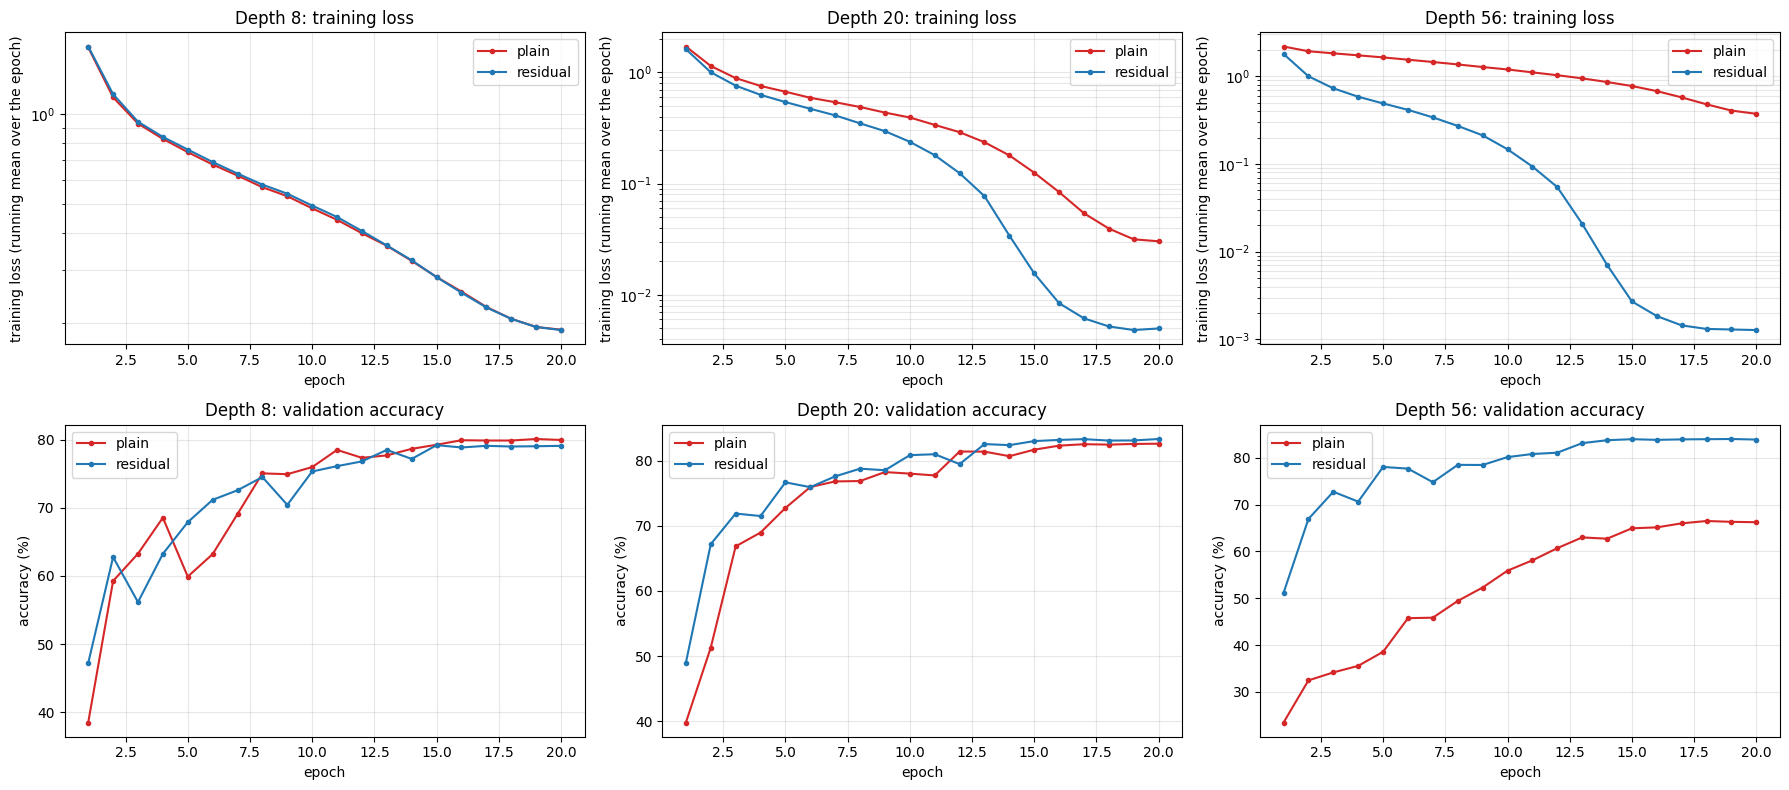

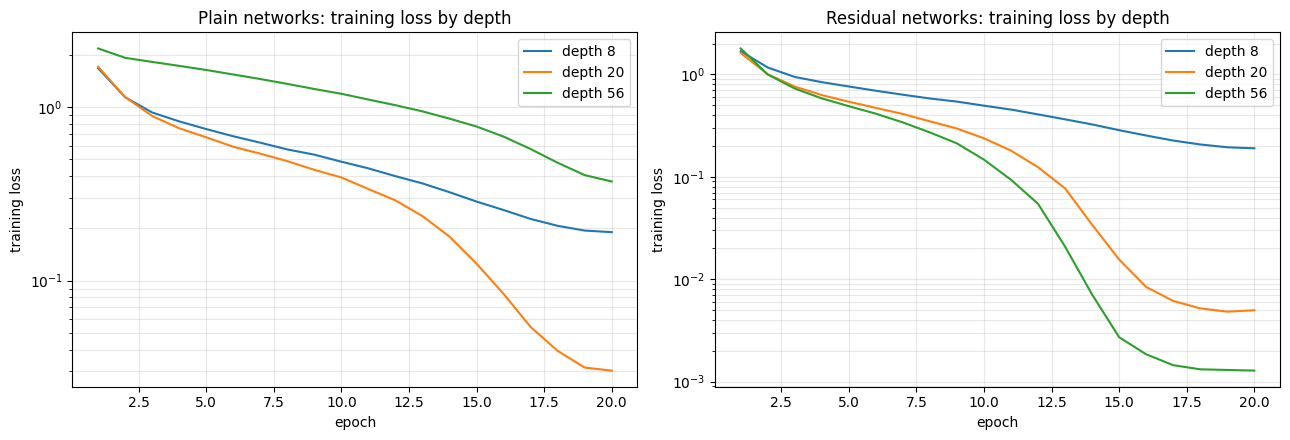

 depth    family    params  train loss @ep1  train loss @ep5  final train loss  final val acc (%)
     8     plain    75,290           1.6736           0.7465            0.1901              79.94
     8  residual    75,290           1.6842           0.7616            0.1896              79.08
    20     plain   269,722           1.7075           0.6696            0.0303              82.64
    20  residual   269,722           1.6167           0.5404            0.0050              83.36
    56     plain   853,018           2.1769           1.6359            0.3724              66.24
    56  residual   853,018           1.7910           0.4888            0.0013              83.88


In [22]:
ep = np.arange(1, EPOCHS_B + 1)
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for c, n in enumerate(DEPTHS):
    for residual, col in ((False, 'tab:red'), (True, 'tab:blue')):
        h = results_b[(n, residual)]; lab = 'residual' if residual else 'plain'
        ax[0, c].plot(ep, h['tr_loss'], 'o-', ms=3, color=col, label=lab)
        ax[1, c].plot(ep, h['va_acc'], 'o-', ms=3, color=col, label=lab)
    ax[0, c].set(title=f'Depth {6 * n + 2}: training loss', xlabel='epoch', ylabel='training loss (running mean over the epoch)', yscale='log')
    ax[1, c].set(title=f'Depth {6 * n + 2}: validation accuracy', xlabel='epoch', ylabel='accuracy (%)')
    for r in (0, 1): ax[r, c].grid(alpha=.3, which='both'); ax[r, c].legend()
plt.tight_layout(); plt.show()

# all depths together per family: the degradation problem shows as plain-56 above plain-20
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, residual in zip(ax, (False, True)):
    for n in DEPTHS: a.plot(ep, results_b[(n, residual)]['tr_loss'], label=f'depth {6 * n + 2}')
    a.set(title=f"{'Residual' if residual else 'Plain'} networks: training loss by depth", xlabel='epoch', ylabel='training loss', yscale='log')
    a.grid(alpha=.3, which='both'); a.legend()
plt.tight_layout(); plt.show()

print(f"{'depth':>6}{'family':>10}{'params':>10}{'train loss @ep1':>17}{'train loss @ep5':>17}{'final train loss':>18}{'final val acc (%)':>19}")
for n in DEPTHS:
    for residual in (False, True):
        h = results_b[(n, residual)]; P = sum(p.numel() for p in make(n, residual).parameters())
        print(f"{6 * n + 2:>6}{'residual' if residual else 'plain':>10}{P:>10,}{h['tr_loss'][0]:>17.4f}{h['tr_loss'][4]:>17.4f}{h['tr_loss'][-1]:>18.4f}{h['va_acc'][-1]:>19.2f}")

### Interpretation of 3(b)

**Plain networks.** At depth 8 the final training loss is 0.190 and at depth 20 it is 0.030, so a deeper plain network still fits better there. However at depth 56 it is 0.372, higher than both. This is the training loss, so it cannot be overfitting. It is an optimisation failure, often called the degradation problem. The network also starts slowly, with an epoch 1 loss of 2.18 (chance is 2.30) and an epoch 5 loss of 1.64. Its validation accuracy falls to 66.2% (79.9% at depth 8 and 82.6% at depth 20).

**Residual networks.** At depth 8 the residual network behaves like the plain one (training loss 0.190 and validation accuracy 79.1%). At depth 20 it trains faster (epoch 5 loss 0.540 against 0.670 and final loss 0.0050 against 0.0303). At depth 56 it reaches the lowest training loss of all six models (0.0013) and 83.9% validation accuracy, which is 17.6 points above the plain network of the same depth. It gains only 0.5 points over depth 20 (83.4%), so the extra depth mainly helps optimisation.

**Why the shortcut helps.** A block outputs $x+F(x)$ so $\partial L/\partial x=\partial L/\partial y\,(I+\partial F/\partial x)$ and the gradient always has a direct path back. In the plain network it must pass through 56 transformations. At initialisation the gradient norm of the first convolution is 510 times that of the last block in the plain network of depth 56 (377 against 0.74) but only 2.0 times in the residual one. Hence shortcuts keep the gradient scale even across layers and matter more as the depth grows.

# Task 4 Best CNN under 500k parameters and 20 epochs

I use a residual network of depth 20 with widths 20, 40 and 80 (420,670 parameters, the next size up would have 508,672), flip and crop plus a small cutout, label smoothing 0.1, and SGD with Nesterov momentum, warm up and cosine decay. I tune on the validation split, ablate seven choices and use the test set once.

In [23]:
# ===================== Task 4: model, configuration and training function =====================
MAX_PARAMS, MAX_EPOCHS = 500_000, 20
USE_AMP = device.type == 'cuda'                      # fp16 mixed precision on the GPU only
try:    make_scaler = lambda: torch.amp.GradScaler('cuda', enabled=USE_AMP)
except AttributeError: make_scaler = lambda: torch.cuda.amp.GradScaler(enabled=USE_AMP)

def count_params(m): return sum(p.numel() for p in m.parameters())

class ResNetW(nn.Module):
    '''CIFAR ResNet of depth 6n+2 with configurable stage widths. Reuses Block from Task 3(b) (option-A shortcut).
    residual=False gives the plain network (identical parameters, no shortcut).'''
    def __init__(self, n=3, widths=(20, 40, 80), residual=True, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, cin = [], widths[0]
        for si, cout in enumerate(widths):
            for b in range(n):
                blocks.append(Block(cin, cout, 2 if (b == 0 and si > 0) else 1, residual)); cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], n_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if isinstance(m, nn.Linear): nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

# parameter budget check for a few candidate sizes (depth 20 unless stated)
for n, w in [(3, (16, 32, 64)), (3, (20, 40, 80)), (3, (22, 44, 88)), (4, (18, 36, 72)), (4, (20, 40, 80))]:
    p = count_params(ResNetW(n, w))
    print(f'depth {6*n+2:>2}, widths {w}: {p:>9,} parameters  ->  {"within budget" if p <= MAX_PARAMS else "OVER the 500k budget"}')

BASE = dict(n=3, widths=(20, 40, 80), residual=True, opt='sgd', lr=0.1, wd=5e-4,
            flipcrop=True, cutout=8, ls=0.1)          # cutout = square side in pixels (0 = off); ls = label smoothing

def train_net(cfg, seed, epochs=MAX_EPOCHS, bs=128, verbose=False):
    '''Train on the 45k split. Returns (history, final-epoch state_dict on CPU). Validation is measured after every epoch.'''
    assert epochs <= MAX_EPOCHS, 'at most 20 epochs allowed'
    set_seed(seed)
    model = ResNetW(cfg['n'], cfg['widths'], cfg['residual']).to(device).to(memory_format=torch.channels_last)
    n_par = count_params(model); assert n_par <= MAX_PARAMS, f'{n_par} parameters > {MAX_PARAMS}'
    if cfg['opt'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    else:
        opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    scaler = make_scaler()
    N = len(X_tr); steps_per_ep = N // bs; total = epochs * steps_per_ep; warm = steps_per_ep      # 1 warm-up epoch, then cosine to 0
    lr_at = lambda t: cfg['lr'] * (t + 1) / warm if t < warm else 0.5 * cfg['lr'] * (1 + math.cos(math.pi * (t - warm) / (total - warm)))
    hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False, params=n_par); step = 0
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, steps_per_ep * bs, bs):
            for g in opt.param_groups: g['lr'] = lr_at(step)
            idx = order[i:i + bs]; x, y = X_tr[idx], y_tr[idx]
            if cfg['flipcrop']: x = random_crop(random_flip(x))          # hand-written augmentations from Task 3(a)
            if cfg['cutout']:   x = cutout(x, size=cfg['cutout'])
            x = x.contiguous(memory_format=torch.channels_last)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                loss = F.cross_entropy(model(x), y, label_smoothing=cfg['ls'])
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.detach() * bs; step += 1
        tr = run.item() / (steps_per_ep * bs)
        if not math.isfinite(tr):                                      # diverged: stop and count as chance accuracy
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0):
            print(f'    epoch {ep+1:2d}/{epochs}  train loss {tr:.4f}  val loss {vl:.4f}  val acc {va:.2f}%')
    return hist, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

depth 20, widths (16, 32, 64):   269,722 parameters  ->  within budget
depth 20, widths (20, 40, 80):   420,670 parameters  ->  within budget
depth 20, widths (22, 44, 88):   508,672 parameters  ->  OVER the 500k budget
depth 26, widths (18, 36, 72):   463,996 parameters  ->  within budget
depth 26, widths (20, 40, 80):   572,430 parameters  ->  OVER the 500k budget


## Task 4 Step 1 Tuning

A small grid over the peak learning rate (0.05, 0.1, 0.2) and weight decay (0.0005, 0.001), one seed each, picking the best final validation accuracy.

In [24]:
TUNE_SEED = 0
GRID = [(lr, wd) for lr in (0.05, 0.1, 0.2) for wd in (5e-4, 1e-3)]
tune, tune_sd = {}, {}
t0 = time.time()
for lr, wd in GRID:
    cfg = {**BASE, 'lr': lr, 'wd': wd}
    tune[(lr, wd)], tune_sd[(lr, wd)] = train_net(cfg, TUNE_SEED)
    h = tune[(lr, wd)]
    print(f"lr={lr:<5g} wd={wd:<7g}  final train loss {h['tr_loss'][-1]:.4f}  final val acc {h['va_acc'][-1]:.2f}%  "
          f"best-epoch val acc {max(h['va_acc']):.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time()-t0:.0f}s]")

best_key = max(tune, key=lambda k: tune[k]['va_acc'][-1])
best_lr, best_wd = best_key
FINAL = {**BASE, 'lr': best_lr, 'wd': best_wd}
print(f"\nSelected on validation: lr={best_lr:g}, wd={best_wd:g}  ->  {tune[best_key]['va_acc'][-1]:.2f}%   "
      f"({tune[best_key]['params']:,} parameters, {MAX_EPOCHS} epochs)")

lr=0.05  wd=0.0005   final train loss 0.7356  final val acc 88.92%  best-epoch val acc 89.12%   [136s]
lr=0.05  wd=0.001    final train loss 0.7096  final val acc 90.10%  best-epoch val acc 90.18%   [271s]
lr=0.1   wd=0.0005   final train loss 0.7005  final val acc 90.04%  best-epoch val acc 90.18%   [406s]
lr=0.1   wd=0.001    final train loss 0.6941  final val acc 91.20%  best-epoch val acc 91.36%   [541s]
lr=0.2   wd=0.0005   final train loss 0.6882  final val acc 90.88%  best-epoch val acc 90.92%   [676s]
lr=0.2   wd=0.001    final train loss 0.7133  final val acc 90.52%  best-epoch val acc 90.52%   [811s]

Selected on validation: lr=0.1, wd=0.001  ->  91.20%   (420,670 parameters, 20 epochs)


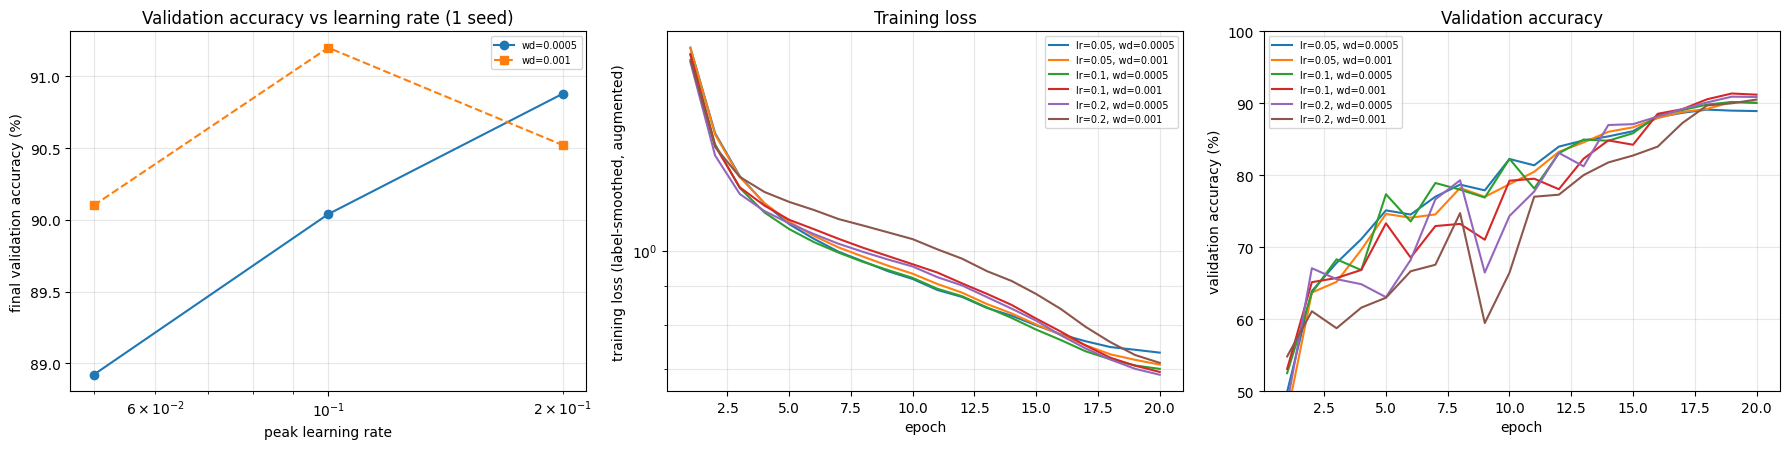

    lr       wd  final train loss  final val acc (%)  best-epoch val acc (%)
  0.05   0.0005            0.7356              88.92                   89.12
  0.05    0.001            0.7096              90.10                   90.18
   0.1   0.0005            0.7005              90.04                   90.18
   0.1    0.001            0.6941              91.20                   91.36   <- selected
   0.2   0.0005            0.6882              90.88                   90.92
   0.2    0.001            0.7133              90.52                   90.52


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for wd, mk in zip((5e-4, 1e-3), ('o-', 's--')):
    lrs = [lr for lr, w in GRID if w == wd]
    ax[0].plot(lrs, [tune[(lr, wd)]['va_acc'][-1] for lr in lrs], mk, label=f'wd={wd:g}')
ax[0].set(xscale='log', xlabel='peak learning rate', ylabel='final validation accuracy (%)', title='Validation accuracy vs learning rate (1 seed)')
ep = np.arange(1, MAX_EPOCHS + 1)
for (lr, wd), h in tune.items():
    ax[1].plot(ep, h['tr_loss'], label=f'lr={lr:g}, wd={wd:g}'); ax[2].plot(ep, h['va_acc'], label=f'lr={lr:g}, wd={wd:g}')
ax[1].set(xlabel='epoch', ylabel='training loss (label-smoothed, augmented)', title='Training loss', yscale='log')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy', ylim=(50, 100))
for a in ax: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'lr':>6}{'wd':>9}{'final train loss':>18}{'final val acc (%)':>19}{'best-epoch val acc (%)':>24}")
for (lr, wd), h in tune.items():
    print(f"{lr:>6g}{wd:>9g}{h['tr_loss'][-1]:>18.4f}{h['va_acc'][-1]:>19.2f}{max(h['va_acc']):>24.2f}" + ('   <- selected' if (lr, wd) == best_key else ''))

## Task 4 Step 2 Ablation

I remove one design choice at a time with the same schedule and two seeds, and report validation accuracy and the change from the full model. The Adam row uses untuned defaults.

In [26]:
ABL_SEEDS = (0, 1)           # set to (0,) to halve the runtime; differences smaller than about 1-2 seed stds are then inconclusive
VARIANTS = {
    'full model':              {},
    'no shortcut (plain)':     dict(residual=False),
    'no augmentation':         dict(flipcrop=False, cutout=0),
    'no cutout':               dict(cutout=0),
    'no weight decay':         dict(wd=0.0),
    'no label smoothing':      dict(ls=0.0),
    'Adam instead of SGD':     dict(opt='adam', lr=1e-3, wd=1e-4),
    'narrower (16/32/64)':     dict(widths=(16, 32, 64)),
}
abl, full_sd = {}, {}
t0 = time.time()
for name, delta in VARIANTS.items():
    for seed in ABL_SEEDS:
        if name == 'full model' and seed == TUNE_SEED:                    # identical run already done during tuning
            h, sd = tune[best_key], tune_sd[best_key]
        else:
            h, sd = train_net({**FINAL, **delta}, seed)
        abl[(name, seed)] = h
        if name == 'full model': full_sd[seed] = sd
        print(f"{name:<22} seed={seed}  params {h['params']:>7,}  final train loss {h['tr_loss'][-1]:.4f}  "
              f"final val acc {h['va_acc'][-1]:.2f}%  {'DIVERGED' if h['diverged'] else ''} [{time.time()-t0:.0f}s]")

full model             seed=0  params 420,670  final train loss 0.6941  final val acc 91.20%   [0s]
full model             seed=1  params 420,670  final train loss 0.6978  final val acc 90.86%   [135s]
no shortcut (plain)    seed=0  params 420,670  final train loss 0.7494  final val acc 88.12%   [262s]
no shortcut (plain)    seed=1  params 420,670  final train loss 0.7548  final val acc 88.78%   [389s]
no augmentation        seed=0  params 420,670  final train loss 0.5182  final val acc 87.36%   [519s]
no augmentation        seed=1  params 420,670  final train loss 0.5182  final val acc 87.52%   [650s]
no cutout              seed=0  params 420,670  final train loss 0.6498  final val acc 90.78%   [783s]
no cutout              seed=1  params 420,670  final train loss 0.6563  final val acc 90.56%   [916s]
no weight decay        seed=0  params 420,670  final train loss 0.7635  final val acc 87.84%   [1050s]
no weight decay        seed=1  params 420,670  final train loss 0.7537  final val a

variant                  params      val acc (%)  change vs full  final train loss  best-epoch val acc
full model              420,670    91.03 ± 0.17            +0.00            0.6959               91.11
no shortcut (plain)     420,670    88.45 ± 0.33            -2.58            0.7521               88.54
no augmentation         420,670    87.44 ± 0.08            -3.59            0.5182               87.48
no cutout               420,670    90.67 ± 0.11            -0.36            0.6531               90.68
no weight decay         420,670    87.76 ± 0.08            -3.27            0.7586               87.92
no label smoothing      420,670    90.60 ± 0.08            -0.43            0.2355               90.62
Adam instead of SGD     420,670    86.71 ± 0.01            -4.32            0.8047               86.74
narrower (16/32/64)     269,722    89.54 ± 0.20            -1.49            0.7327               89.54


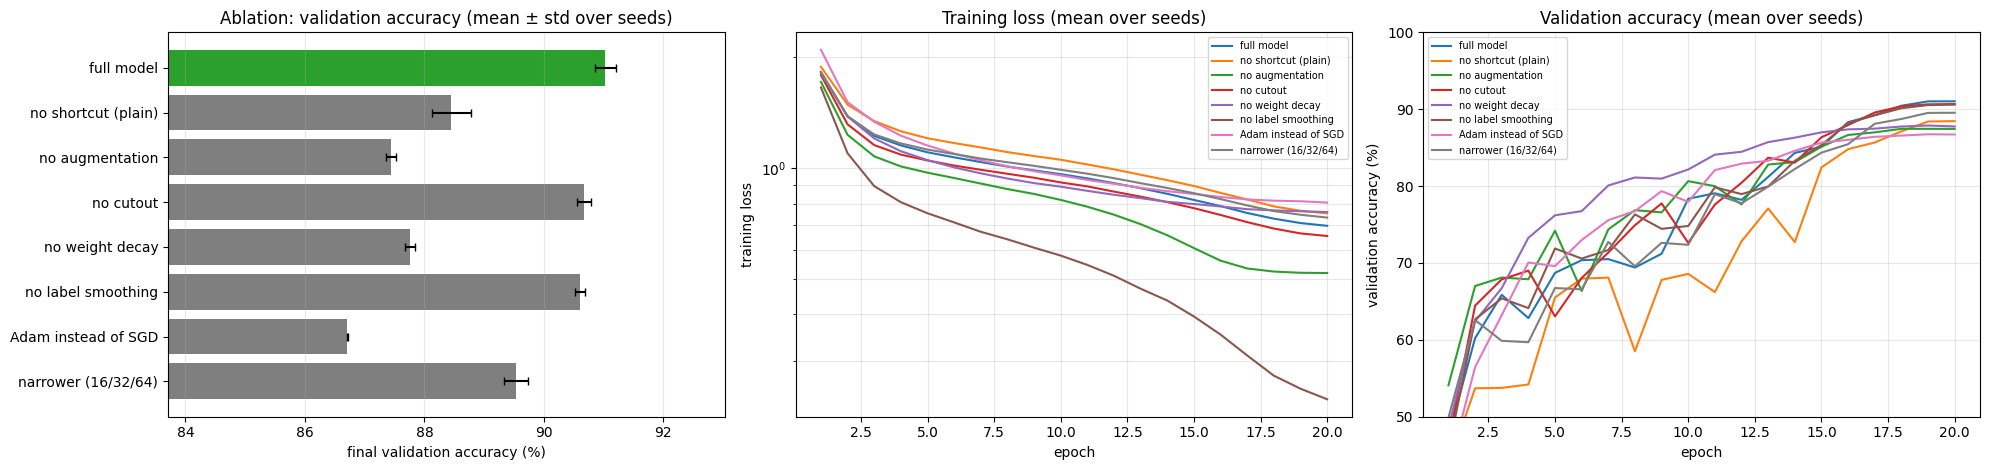

In [27]:
def stk(name, key): return np.array([abl[(name, s)][key] for s in ABL_SEEDS], dtype=float)      # (seeds, epochs)
full_acc = stk('full model', 'va_acc')[:, -1]
print(f"{'variant':<22}{'params':>9}{'val acc (%)':>17}{'change vs full':>16}{'final train loss':>18}{'best-epoch val acc':>20}")
rows = []
for name in VARIANTS:
    acc = stk(name, 'va_acc')[:, -1]; trl = np.nanmean(stk(name, 'tr_loss')[:, -1]); best = stk(name, 'va_acc').max(1).mean()
    rows.append((name, acc.mean(), acc.std()))
    print(f"{name:<22}{abl[(name, ABL_SEEDS[0])]['params']:>9,}{acc.mean():>9.2f} ± {acc.std():<5.2f}{acc.mean() - full_acc.mean():>+16.2f}{trl:>18.4f}{best:>20.2f}")

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
names = [r[0] for r in rows]; means = [r[1] for r in rows]; stds = [r[2] for r in rows]
ax[0].barh(range(len(rows)), means, xerr=stds, color=['tab:green'] + ['tab:gray'] * (len(rows) - 1), capsize=3)
ax[0].set_yticks(range(len(rows))); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
ax[0].set(xlim=(min(means) - 3, max(means) + 2), xlabel='final validation accuracy (%)', title='Ablation: validation accuracy (mean ± std over seeds)')
cmap = plt.get_cmap('tab10')
for k, name in enumerate(VARIANTS):
    ax[1].plot(np.arange(1, MAX_EPOCHS + 1), np.nanmean(stk(name, 'tr_loss'), 0), color=cmap(k), label=name)
    ax[2].plot(np.arange(1, MAX_EPOCHS + 1), np.nanmean(stk(name, 'va_acc'), 0), color=cmap(k), label=name)
ax[1].set(xlabel='epoch', ylabel='training loss', yscale='log', title='Training loss (mean over seeds)')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy (mean over seeds)', ylim=(50, 100))
for a in ax[1:]: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
ax[0].grid(alpha=.3, axis='x')
plt.tight_layout(); plt.show()

## Task 4 Step 3 Final test result

The final model is the better full model run by validation accuracy. The test set is evaluated once and the cell refuses to run a second time.

Final model: ResNet-20, widths (20, 40, 80), 420,670 parameters (limit 500,000), 20 epochs, lr=0.1, wd=0.001, flip+crop, cutout 8px, label smoothing 0.1
Validation accuracy of this model: 91.20%
TEST accuracy (evaluated once): 90.37%   test loss 0.3417

Per-class test accuracy:
  airplane    91.30%
  automobile  95.80%
  bird        88.40%
  cat         78.20%
  deer        90.70%
  dog         84.40%
  frog        93.30%
  horse       92.80%
  ship        95.10%
  truck       93.70%


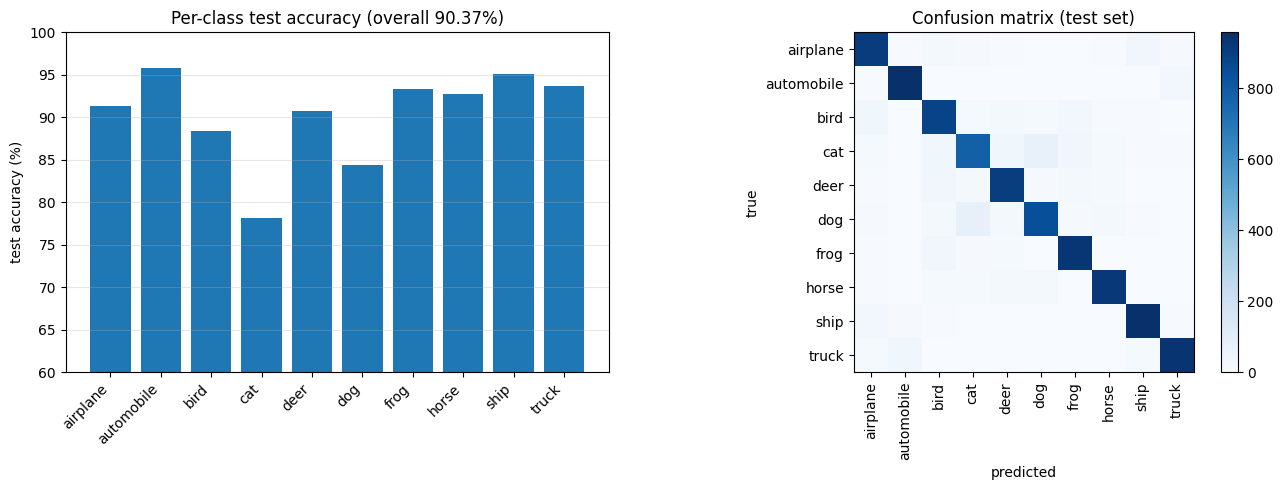

In [28]:
assert not globals().get('TEST_DONE', False), 'The test set has already been evaluated once in this session. Do not run this cell again.'

# 1) choose the final model by VALIDATION accuracy among the full-model runs
final_seed = max(ABL_SEEDS, key=lambda s: abl[('full model', s)]['va_acc'][-1])
final_model = ResNetW(FINAL['n'], FINAL['widths'], FINAL['residual']).to(device).to(memory_format=torch.channels_last)
final_model.load_state_dict(full_sd[final_seed]); final_model.eval()
n_par = count_params(final_model); assert n_par <= MAX_PARAMS
val_acc_final = abl[('full model', final_seed)]['va_acc'][-1]

# 2) load the test set (same normalisation statistics as the training split) and evaluate in ONE pass
test_raw = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
X_te = torch.from_numpy(test_raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()
y_te = torch.tensor(test_raw.targets, dtype=torch.long)
X_te, y_te = ((X_te - mean) / std).to(device), y_te.to(device)
with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
    logits = torch.cat([final_model(X_te[i:i + 1000].contiguous(memory_format=torch.channels_last)).float() for i in range(0, len(X_te), 1000)])
TEST_DONE = True                                                      # from here on the cell is locked

pred = logits.argmax(1)
test_acc = 100.0 * (pred == y_te).float().mean().item()
test_loss = F.cross_entropy(logits, y_te).item()
conf = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(y_te.cpu(), pred.cpu()): conf[t, p] += 1
per_class = 100.0 * conf.diag().float() / conf.sum(1).float()

print(f'Final model: ResNet-20, widths {FINAL["widths"]}, {n_par:,} parameters (limit {MAX_PARAMS:,}), {MAX_EPOCHS} epochs, '
      f'lr={FINAL["lr"]:g}, wd={FINAL["wd"]:g}, flip+crop, cutout {FINAL["cutout"]}px, label smoothing {FINAL["ls"]}')
print(f'Validation accuracy of this model: {val_acc_final:.2f}%')
print(f'TEST accuracy (evaluated once): {test_acc:.2f}%   test loss {test_loss:.4f}')
print('\nPer-class test accuracy:')
for c, a in zip(test_raw.classes, per_class.tolist()): print(f'  {c:<11}{a:6.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(range(10), per_class.numpy(), color='tab:blue'); ax[0].set_xticks(range(10)); ax[0].set_xticklabels(test_raw.classes, rotation=45, ha='right')
ax[0].set(ylabel='test accuracy (%)', title=f'Per-class test accuracy (overall {test_acc:.2f}%)', ylim=(60, 100)); ax[0].grid(alpha=.3, axis='y')
im = ax[1].imshow(conf.numpy(), cmap='Blues'); ax[1].set_xticks(range(10)); ax[1].set_yticks(range(10))
ax[1].set_xticklabels(test_raw.classes, rotation=90); ax[1].set_yticklabels(test_raw.classes)
ax[1].set(xlabel='predicted', ylabel='true', title='Confusion matrix (test set)'); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

### Interpretation of Task 4

**Tuning.** The grid picked a learning rate of 0.1 with weight decay 0.001 (91.20% validation). However five of the six settings lie within about 1.2 points, so this choice is not clearly better than its neighbours. 

**Ablation.** The full model gets 91.03% over two seeds. Switching from SGD to Adam costs the most (4.32 points), followed by removing augmentation (3.59), weight decay (3.27), the shortcut (2.58) and narrowing the network to 269,722 parameters (1.49). Label smoothing (0.43) and cutout (0.36) matter much less and are weak evidence. Also the Adam row is untuned and changes weight decay as well, so it is not a fair comparison. Without augmentation the training loss is lower (0.518 against 0.696) but validation accuracy is 3.6 points lower, which is overfitting.

**Final model.** It has 420,670 parameters and reaches 90.37% on the test set against 91.20% on validation. This 0.8 point drop is small and expected after tuning on the validation split. Therefore the test result is reliable to within about one point. Cats (78.2%) and dogs (84.4%) are the weakest classes while automobiles (95.8%) and ships (95.1%) are the strongest.